# Actividad 8 · VOREKO IA · Monitorización proactiva, alertas inteligentes y respuesta automatizada
**José Ignacio Castillo Camacho · AL07161745**

## 1. Instalación de dependencias

In [1]:
import os
import subprocess
import sys

os.environ["MLFLOW_DISABLE_AGENT_HINT"] = "1"
PAQUETES = ["scikit-learn==1.9.1", "xgboost==3.4.1", "mlflow==3.18.0", "opentelemetry-sdk==1.45.2", "pyyaml", "scipy", "matplotlib"]
subprocess.run([sys.executable, "-m", "pip", "install", "-q", *PAQUETES], check=True)

CompletedProcess(args=['/usr/local/bin/python3.13', '-m', 'pip', 'install', '-q', 'scikit-learn==1.9.1', 'xgboost==3.4.1', 'mlflow==3.18.0', 'opentelemetry-sdk==1.45.2', 'pyyaml', 'scipy', 'matplotlib'], returncode=0)

## 2. Descarga del repositorio VOREKO y reproducción del modelo de la Fase II

In [2]:
import json
import shutil
import time
import logging
import warnings
from pathlib import Path
from datetime import datetime, timedelta

warnings.filterwarnings("ignore")
BASE = Path.cwd()
REPO = BASE / "voreko-ia-incidencias"
if not REPO.exists():
    subprocess.run(["git", "clone", "--depth", "1", "https://github.com/Ignacio-Castillo-C/voreko-ia-incidencias.git", str(REPO)], check=True)

SALIDA = BASE / "actividad8_salidas"
if SALIDA.exists():
    shutil.rmtree(SALIDA)
for carpeta in ["artefactos/v1", "config", "logs", "trazas", "figuras", "tablas"]:
    (SALIDA / carpeta).mkdir(parents=True, exist_ok=True)

entrenamiento = subprocess.run([sys.executable, str(REPO / "FaseII" / "modelo" / "entrenar_modelo.py"), "--salida", str(SALIDA / "artefactos" / "v1")],
                               capture_output=True, text=True, cwd=REPO)
print("\n".join(l for l in entrenamiento.stdout.splitlines() if l.startswith("OK")))
assert entrenamiento.returncode == 0, entrenamiento.stderr[-2000:]

Cloning into '/content/voreko-ia-incidencias'...


OK  El modelo empaquetado da las mismas probabilidades que el pipeline de la Actividad 6 en las 75 obras de prueba (diferencia < 1e-12)
OK  Umbral de decisión reproducido: 0.39
OK  recall en prueba reproducido: 0.538
OK  precision en prueba reproducido: 0.560
OK  roc_auc en prueba reproducido: 0.803


## 3. Datos de referencia y obras que llegan a producción

In [3]:
import numpy as np
import pandas as pd
import joblib
import yaml
from scipy.stats import ks_2samp
from scipy.spatial.distance import jensenshannon
from sklearn.base import clone
from sklearn.metrics import recall_score, precision_score, roc_auc_score

sys.path.insert(0, str(REPO / "Actividad6" / "fuentes"))
import voreko_a6 as v

META_V1 = json.loads((SALIDA / "artefactos" / "v1" / "metadatos_modelo.json").read_text(encoding="utf-8"))
COLUMNAS = [c["nombre"] for c in META_V1["variables"]]
CATEGORICAS = META_V1["variables_categoricas"]
U_ROJO, U_AMARILLO = META_V1["umbrales"]["rojo"], META_V1["umbrales"]["amarillo"]

df, _ = v.cargar_datos_a5()
X_todo = v.variables_inicio(df)
y_todo = v.construir_etiqueta(df)
idx_tr, idx_te = v.particion_a5(X_todo, df["costo_real_m2"])
X_tr, X_te = X_todo.loc[idx_tr, COLUMNAS].reset_index(drop=True), X_todo.loc[idx_te, COLUMNAS].reset_index(drop=True)
y_tr, y_te = y_todo.loc[idx_tr].reset_index(drop=True), y_todo.loc[idx_te].reset_index(drop=True)
ID_TE = df.loc[idx_te, "id_proyecto"].to_numpy()

MONETARIAS = ["costo_prelim_m2", "costo_prelim_m2_base", "precio_venta_inicial_m2", "indice_servicios_construccion_r1",
              "indice_precios_materiales_r1", "liquidez_acumulada_r1", "inversion_privada_edificacion_r1", "indice_precio_suelo_r1",
              "monto_creditos_r1", "costo_promedio_fin_m2_r1", "costo_promedio_inicio_m2_r1", "inpc_r1", "inpc_vivienda_r1",
              "indice_bolsa_r1", "precio_oro_onza_r1"]
SIN_RUIDO = ["anio_inicio", "trimestre_inicio", "localidad", "indice_tiempo_inicio"]
CONTINUAS = [c for c in COLUMNAS if c not in SIN_RUIDO]
VARS_DRIFT = CONTINUAS

modelo_v1 = joblib.load(SALIDA / "artefactos" / "v1" / "modelo_riesgo.joblib")
modelo_v1.named_steps["modelo"].set_params(n_jobs=1)
p_v1 = modelo_v1.predict_proba(X_te)[:, 1]
REF_V1 = {"recall": recall_score(y_te, p_v1 >= U_ROJO), "precision": precision_score(y_te, p_v1 >= U_ROJO), "roc_auc": roc_auc_score(y_te, p_v1)}
print({k: round(x, 3) for k, x in REF_V1.items()}, "| obras entrenamiento:", len(X_tr), "| obras producción:", len(X_te), "| variables:", len(COLUMNAS))

{'recall': 0.538, 'precision': 0.56, 'roc_auc': 0.803} | obras entrenamiento: 297 | obras producción: 75 | variables: 28


## 4. Configuración de SLO y reglas de alerta

In [4]:
CONFIG_YAML = """
servicio: voreko-ia-riesgo-sobrecosto
periodo_slo_horas: 24
ventana_minutos: 15
slo:
  disponibilidad:
    objetivo: 0.995
    sli: solicitudes sin error de servidor / solicitudes totales
  latencia:
    objetivo: 0.95
    umbral_ms: 300
    sli: solicitudes con latencia menor a 300 ms / solicitudes totales
  calidad:
    recall_minimo: 0.45
    precision_minima: 0.40
    ventanas_moviles: 4
  datos:
    psi_umbral: 0.20
    ks_umbral: 0.10
    pct_variables_max: 0.30
    psi_leve: 0.18
    ventanas_moviles: 4
burn_rate:
  ventana_corta: 1
  ventana_larga: 4
reglas:
  - nombre: disponibilidad_burn_rate
    severidad: P1
    expr: burn_disp_corta >= 10 and burn_disp_larga >= 5
    para_ventanas: 1
    slo: disponibilidad
    runbook: RB-04
    accion: reiniciar_servicio
    canales: [llamada, slack]
  - nombre: canary_degradado
    severidad: P1
    expr: canary_activo == 1 and canary_n >= 15 and razon_rojo_canary < 0.5
    para_ventanas: 1
    slo: calidad
    runbook: RB-03
    accion: rollback_modelo
    canales: [llamada, slack]
  - nombre: latencia_burn_rate
    severidad: P2
    expr: burn_lat_corta >= 6 and burn_lat_larga >= 2
    para_ventanas: 1
    slo: latencia
    runbook: RB-02
    accion: escalar_replicas
    canales: [slack, correo]
  - nombre: calidad_recall_bajo
    severidad: P2
    expr: recall_movil < 0.45
    para_ventanas: 2
    slo: calidad
    runbook: RB-01
    accion: reentrenar_modelo
    canales: [slack, correo]
  - nombre: drift_datos
    severidad: P3
    expr: n_drift >= 200 and pct_vars_drift > 0.30 and psi_global > 0.20
    para_ventanas: 1
    slo: datos
    runbook: RB-01
    accion: notificar
    canales: [correo]
  - nombre: cpu_saturacion
    severidad: P3
    expr: cpu >= 0.85
    para_ventanas: 2
    slo: latencia
    runbook: RB-02
    accion: notificar
    canales: [correo]
  - nombre: latencia_umbral_dinamico
    severidad: P3
    expr: p95_ms > umbral_dinamico_p95
    para_ventanas: 2
    slo: latencia
    runbook: RB-02
    accion: notificar
    canales: [correo]
  - nombre: presupuesto_latencia_bajo
    severidad: P3
    expr: presupuesto_lat_restante < 0.25
    para_ventanas: 1
    slo: latencia
    runbook: RB-02
    accion: notificar
    canales: [correo]
  - nombre: drift_leve
    severidad: INFO
    expr: n_drift >= 200 and psi_global > 0.18
    para_ventanas: 1
    slo: datos
    runbook: ninguno
    accion: tablero
    canales: [tablero]
correlaciones:
  - incidente: degradacion_por_drift
    reglas: [drift_datos, calidad_recall_bajo]
  - incidente: saturacion_servicio
    reglas: [latencia_burn_rate, cpu_saturacion, latencia_umbral_dinamico, presupuesto_latencia_bajo]
  - incidente: version_defectuosa
    reglas: [canary_degradado]
  - incidente: caida_servicio
    reglas: [disponibilidad_burn_rate]
reduccion_ruido:
  deduplicacion: true
  resolver_tras_ventanas_limpias: 2
  umbral_dinamico:
    metrica: p95_ms
    historial_ventanas: 12
    desviaciones: 3
alertas_ingenuas:
  - nombre: p95_mayor_300
    expr: p95_ms > 300
  - nombre: error_servidor
    expr: errores_servidor >= 1
  - nombre: recall_ventana_bajo
    expr: recall_ventana < 0.45
  - nombre: psi_variable_alto
    expr: psi_max_ventana > 0.20
  - nombre: cpu_mayor_80
    expr: cpu > 0.80
  - nombre: pocos_rojos
    expr: tasa_rojo_ventana < 0.20
"""
(SALIDA / "config" / "alert_rules.yaml").write_text(CONFIG_YAML.strip() + "\n", encoding="utf-8")
CONFIG = yaml.safe_load(CONFIG_YAML)
SLO = CONFIG["slo"]
REGLAS = {r["nombre"]: r for r in CONFIG["reglas"]}
REGLA_A_INCIDENTE = {r: c["incidente"] for c in CONFIG["correlaciones"] for r in c["reglas"]}
pd.DataFrame(CONFIG["reglas"]).drop(columns=["canales"]).assign(canales=[", ".join(r["canales"]) for r in CONFIG["reglas"]])

,nombre,severidad,expr,para_ventanas,slo,runbook,accion,canales
0,disponibilidad_burn_rate,P1,burn_disp_corta >= 10 and burn_disp_larga >= 5,1,disponibilidad,RB-04,reiniciar_servicio,"llamada, slack"
1,canary_degradado,P1,canary_activo == 1 and canary_n >= 15 and razo...,1,calidad,RB-03,rollback_modelo,"llamada, slack"
2,latencia_burn_rate,P2,burn_lat_corta >= 6 and burn_lat_larga >= 2,1,latencia,RB-02,escalar_replicas,"slack, correo"
3,calidad_recall_bajo,P2,recall_movil < 0.45,2,calidad,RB-01,reentrenar_modelo,"slack, correo"
4,drift_datos,P3,n_drift >= 200 and pct_vars_drift > 0.30 and p...,1,datos,RB-01,notificar,correo
5,cpu_saturacion,P3,cpu >= 0.85,2,latencia,RB-02,notificar,correo
6,latencia_umbral_dinamico,P3,p95_ms > umbral_dinamico_p95,2,latencia,RB-02,notificar,correo
7,presupuesto_latencia_bajo,P3,presupuesto_lat_restante < 0.25,1,latencia,RB-02,notificar,correo
8,drift_leve,INFO,n_drift >= 200 and psi_global > 0.18,1,datos,ninguno,tablero,tablero


## 5. Registro del modelo en MLflow

In [5]:
import mlflow
import mlflow.sklearn
from mlflow import MlflowClient

logging.getLogger("mlflow").setLevel(logging.ERROR)
mlflow.set_tracking_uri(f"sqlite:///{SALIDA / 'mlflow.db'}")
EXPERIMENTO = "VOREKO_A8_Monitorizacion"
client = MlflowClient()
if client.get_experiment_by_name(EXPERIMENTO) is None:
    client.create_experiment(EXPERIMENTO, artifact_location=(SALIDA / "mlartifacts").as_uri())
mlflow.set_experiment(EXPERIMENTO)
NOMBRE_MODELO = "voreko_riesgo_sobrecosto"


def registrar_version(modelo, nombre_run, u_rojo, u_amarillo, metricas, params, descripcion):
    with mlflow.start_run(run_name=nombre_run, nested=mlflow.active_run() is not None) as run:
        mlflow.log_params({**params, "umbral_rojo": u_rojo, "umbral_amarillo": u_amarillo})
        mlflow.log_metrics(metricas)
        info = mlflow.sklearn.log_model(modelo, name="modelo", registered_model_name=NOMBRE_MODELO, skops_trusted_types=["sklearn.tree._tree.Tree"])
    version = str(info.registered_model_version)
    for k, x in {"umbral_rojo": u_rojo, "umbral_amarillo": u_amarillo, "run_id": run.info.run_id}.items():
        client.set_model_version_tag(NOMBRE_MODELO, version, k, str(x))
    client.update_model_version(NOMBRE_MODELO, version, description=descripcion)
    return version


V1 = registrar_version(modelo_v1, "modelo_v1_fase2", U_ROJO, U_AMARILLO, {f"prueba_{k}": x for k, x in REF_V1.items()},
                       {"origen": "Actividad 6 / Fase II", "algoritmo": "RandomForestClassifier", **META_V1["hiperparametros"]},
                       "Modelo estable de la Fase II (umbral 0.39).")
client.set_registered_model_alias(NOMBRE_MODELO, "champion", V1)
print("Versión registrada:", V1, "| alias champion →", client.get_model_version_by_alias(NOMBRE_MODELO, "champion").version)

Versión registrada: 1 | alias champion → 1


Successfully registered model 'voreko_riesgo_sobrecosto'.
Created version '1' of model 'voreko_riesgo_sobrecosto'.


## 6. Observabilidad: logs estructurados y trazas

In [6]:
from opentelemetry import trace
from opentelemetry.sdk.resources import Resource
from opentelemetry.sdk.trace import TracerProvider
from opentelemetry.sdk.trace.export import SimpleSpanProcessor
from opentelemetry.sdk.trace.export.in_memory_span_exporter import InMemorySpanExporter
from opentelemetry.trace import Status, StatusCode

exportador = InMemorySpanExporter()
proveedor = TracerProvider(resource=Resource.create({"service.name": "voreko-ia-riesgo-sobrecosto", "deployment.environment": "produccion-simulada"}))
proveedor.add_span_processor(SimpleSpanProcessor(exportador))
tracer = proveedor.get_tracer("voreko.monitorizacion")


class FormatoJSON(logging.Formatter):
    def format(self, r):
        return json.dumps({"timestamp": getattr(r, "ts_sim", ""), "nivel": r.levelname, "evento": r.getMessage(), **getattr(r, "datos", {})},
                          ensure_ascii=False, default=str)


log = logging.getLogger("voreko.servicio")
log.handlers.clear()
log.setLevel(logging.INFO)
log.propagate = False
manejador = logging.FileHandler(SALIDA / "logs" / "servicio.jsonl", mode="w", encoding="utf-8")
manejador.setFormatter(FormatoJSON())
log.addHandler(manejador)


def registrar_log(nivel, evento, ts, **datos):
    log.log(nivel, evento, extra={"ts_sim": ts.isoformat(timespec="seconds"), "datos": datos})


def ns(ts):
    return int(ts.timestamp() * 1e9)

## 7. Servicio de inferencia instrumentado

In [7]:
class ServicioVoreko:
    def __init__(self):
        self.modelos = {}
        self.estable = None
        self.canary = None
        self.pct_canary = 0.0
        self.replicas = 1

    def cargar_alias(self, alias):
        mv = client.get_model_version_by_alias(NOMBRE_MODELO, alias)
        modelo = mlflow.sklearn.load_model(f"models:/{NOMBRE_MODELO}@{alias}")
        modelo.named_steps["modelo"].set_params(n_jobs=1)
        self.modelos[mv.version] = {"modelo": modelo, "u_rojo": float(mv.tags["umbral_rojo"]), "u_amarillo": float(mv.tags["umbral_amarillo"])}
        return mv.version

    def atender(self, fila, ts, ctx_sim, rng):
        version = self.canary if (self.canary and rng.random() < self.pct_canary) else self.estable
        m = self.modelos[version]
        inicio = ns(ts)
        raiz = tracer.start_span("POST /evaluar-obra", start_time=inicio,
                                 attributes={"obra.id": ctx_sim["id_obra"], "modelo.version": version, "servicio.replicas": self.replicas,
                                             "red.ms": round(ctx_sim["red_ms"], 2)})
        ctx = trace.set_span_in_context(raiz)
        cursor = inicio + int(ctx_sim["red_ms"] * 5e5)
        tiempos = {}

        def fase(nombre, funcion, simulado_ms=None, **attrs):
            nonlocal cursor
            sp = tracer.start_span(nombre, context=ctx, start_time=cursor, attributes=attrs)
            t0 = time.perf_counter()
            try:
                resultado = funcion()
                estado_ok = True
            except Exception as e:
                resultado, estado_ok = e, False
                sp.set_status(Status(StatusCode.ERROR, str(e)))
                sp.record_exception(e)
            dur = simulado_ms if simulado_ms is not None else (time.perf_counter() - t0) * 1000
            cursor += int(dur * 1e6)
            sp.end(end_time=cursor)
            tiempos[nombre] = dur
            return resultado, estado_ok

        def validar():
            if fila.isna().any().any() or (fila[["area_construida_m2", "area_terreno_m2", "costo_prelim_m2"]] <= 0).any().any():
                raise ValueError("payload inválido")
            return True

        _, ok_val = fase("validacion", validar)
        estado, prob, semaforo = 200, np.nan, "sin_respuesta"
        if not ok_val:
            estado = 422
        else:
            fase("cola_espera", lambda: None, simulado_ms=ctx_sim["cola_ms"])
            matriz, _ = fase("preprocesamiento", lambda: m["modelo"].named_steps["prep"].transform(fila))

            def inferir():
                if ctx_sim["error_servidor"]:
                    raise RuntimeError("timeout del trabajador de inferencia")
                return float(m["modelo"].named_steps["modelo"].predict_proba(matriz)[0, 1])

            prob, ok_inf = fase("inferencia", inferir)
            if not ok_inf:
                estado, prob = 500, np.nan
            else:
                semaforo, _ = fase("semaforo", lambda: "rojo" if prob >= m["u_rojo"] else ("amarillo" if prob >= m["u_amarillo"] else "verde"))
        cursor += int(ctx_sim["red_ms"] * 5e5)
        raiz.set_attribute("http.status_code", estado)
        raiz.set_attribute("semaforo", semaforo)
        if estado >= 500:
            raiz.set_status(Status(StatusCode.ERROR, "error de servidor"))
        raiz.end(end_time=cursor)
        latencia = (cursor - inicio) / 1e6
        trace_id = format(raiz.get_span_context().trace_id, "032x")
        nivel = logging.ERROR if estado >= 500 else (logging.WARNING if estado == 422 else logging.INFO)
        registrar_log(nivel, "evaluacion_obra", ts, trace_id=trace_id, obra=ctx_sim["id_obra"], version_modelo=version, estado_http=estado,
                      probabilidad=None if np.isnan(prob) else round(prob, 4), semaforo=semaforo, latencia_ms=round(latencia, 2),
                      cola_ms=round(ctx_sim["cola_ms"], 2), replicas=self.replicas)
        return {"ts": ts, "trace_id": trace_id, "version": version, "es_canary": version == self.canary, "obra": ctx_sim["id_obra"], "estado": estado,
                "probabilidad": prob, "semaforo": semaforo, "pred_rojo": int(semaforo == "rojo"), "y_real": ctx_sim["y_real"],
                "latencia_ms": latencia, "cola_ms": ctx_sim["cola_ms"], "inferencia_ms": tiempos.get("inferencia", 0.0)}

## 8. Escenario de producción e inyección de fallas

In [8]:
VENTANAS, SOLICITUDES_VENTANA, MIN_VENTANA = 96, 60, 15
INICIO = datetime(2026, 11, 9, 0, 0)
EVENTOS = {"pico_transitorio": 7, "pico_cpu": 20, "inicio_drift": 30, "rafaga_errores": 40, "inicio_latencia": 50, "fin_trafico_alto": 62, "despliegue_canary": 70}
INFLACION = 1.35


def hora(w, minuto=0.0):
    return INICIO + timedelta(minutes=MIN_VENTANA * w + minuto)


def factor_precios(w):
    if w < EVENTOS["inicio_drift"]:
        return 1.0
    return 1.0 + (INFLACION - 1.0) * (0.5 if w == EVENTOS["inicio_drift"] else 1.0)


class Escenario:
    def __init__(self, servicio):
        self.servicio = servicio
        self.escalado_efectivo = None
        self.pendientes = []
        self.rafaga = 2

    def saturado(self, ts, w):
        activo = EVENTOS["inicio_latencia"] <= w < EVENTOS["fin_trafico_alto"] and ts >= hora(EVENTOS["inicio_latencia"], 1)
        mitigado = self.escalado_efectivo is not None and ts >= self.escalado_efectivo
        return activo and not mitigado

    def condiciones(self, w, minuto, ts, rng, i_obra):
        cola = 0.0
        if self.saturado(ts, w) and rng.random() < 0.7:
            cola = float(rng.lognormal(np.log(400), 0.3))
        if w == EVENTOS["pico_transitorio"] and 3 <= minuto <= 6:
            cola = float(rng.lognormal(np.log(450), 0.2))
        error = rng.random() < 0.001
        if w == EVENTOS["rafaga_errores"] and minuto >= 8 and self.rafaga > 0:
            error, self.rafaga = True, self.rafaga - 1
        return {"red_ms": float(rng.lognormal(np.log(35), 0.35)), "cola_ms": cola, "error_servidor": bool(error),
                "id_obra": str(ID_TE[i_obra]), "y_real": int(y_te.iloc[i_obra])}

    def cpu(self, w, rng):
        if EVENTOS["inicio_latencia"] <= w < EVENTOS["fin_trafico_alto"]:
            return float(np.clip(rng.normal(0.95, 0.02), 0, 1)) if self.saturado(hora(w, 14.9), w) else float(np.clip(rng.normal(0.48, 0.04), 0, 1))
        if w == EVENTOS["pico_cpu"]:
            return 0.88
        return float(np.clip(rng.normal(0.42, 0.05), 0, 1))

    def fila(self, i_obra, w, rng):
        f = X_te.iloc[[i_obra]].copy()
        f[CONTINUAS] = f[CONTINUAS] * (1 + rng.normal(0, 0.01, len(CONTINUAS)))
        f[MONETARIAS] = f[MONETARIAS] * factor_precios(w)
        if rng.random() < 0.003:
            f["costo_prelim_m2"] = -1.0
        return f

    def ejecutar_pendientes(self, ts):
        for item in [p for p in self.pendientes if p[0] <= ts]:
            item[1]()
            self.pendientes.remove(item)

## 9. Detección de data drift

In [9]:
def psi_bins(ref, act, bins=10):
    cortes = np.unique(np.quantile(ref, np.linspace(0, 1, bins + 1)))
    cortes[0], cortes[-1] = -np.inf, np.inf
    r = np.clip(np.histogram(ref, cortes)[0] / len(ref), 1e-4, None)
    a = np.clip(np.histogram(act, cortes)[0] / len(act), 1e-4, None)
    return float(np.sum((a - r) * np.log(a / r))), r, a


def medir_drift(referencia, actual):
    filas = []
    for c in VARS_DRIFT:
        psi, r, a = psi_bins(referencia[c].to_numpy(), actual[c].to_numpy())
        filas.append({"variable": c, "psi": psi, "ks": float(ks_2samp(referencia[c], actual[c]).statistic), "jsd": float(jensenshannon(r, a, base=2) ** 2)})
    t = pd.DataFrame(filas)
    t["drift"] = (t.psi > SLO["datos"]["psi_umbral"]) & (t.ks > SLO["datos"]["ks_umbral"])
    return t


def nivel_drift(psi_global):
    return "severo" if psi_global > 0.5 else ("moderado" if psi_global > SLO["datos"]["psi_umbral"] else ("leve" if psi_global > SLO["datos"]["psi_leve"] else "estable"))


def muestra_sin_drift(n, generador):
    f = X_te.iloc[generador.integers(len(X_te), size=n)].copy()
    f[CONTINUAS] = f[CONTINUAS] * (1 + generador.normal(0, 0.01, f[CONTINUAS].shape))
    return f


rng_calibracion = np.random.default_rng(7)
calibracion = []
for nombre_ref, ref in [("entrenamiento", X_tr), ("validacion", X_te)]:
    for k in range(40):
        t = medir_drift(ref, muestra_sin_drift(240, rng_calibracion))
        calibracion.append({"referencia": nombre_ref, "psi_global": t.psi.mean(), "pct_vars_drift": t.drift.mean(),
                            "falsa_alarma": bool(t.drift.mean() > SLO["datos"]["pct_variables_max"] and t.psi.mean() > SLO["datos"]["psi_umbral"])})
CALIBRACION = pd.DataFrame(calibracion).groupby("referencia").agg(psi_global_medio=("psi_global", "mean"), pct_vars_drift_medio=("pct_vars_drift", "mean"),
                                                                  tasa_falsa_alarma=("falsa_alarma", "mean")).round(3)
REFERENCIA_DRIFT = CALIBRACION.tasa_falsa_alarma.idxmin()
print("Referencia elegida para drift:", REFERENCIA_DRIFT)
CALIBRACION

Referencia elegida para drift: validacion


,psi_global_medio,pct_vars_drift_medio,tasa_falsa_alarma
referencia,,,
entrenamiento,0.184,0.209,0.075
validacion,0.151,0.116,0.000


## 10. Motor de alertas inteligentes y alertas ingenuas

In [10]:
ORDEN_SEV = {"P1": 1, "P2": 2, "P3": 3, "INFO": 4}


class MotorAlertas:
    def __init__(self):
        self.estado = {n: {"activa": False, "seguidas": 0, "limpias": 0} for n in REGLAS}
        self.incidentes, self.notificaciones, self.eventos, self.suprimidas = [], [], [], 0

    def incidente_abierto(self, tipo):
        return next((i for i in self.incidentes if i["tipo"] == tipo and i["cierre"] is None), None)

    def evaluar(self, w, ts, met):
        nuevas = []
        for nombre, regla in REGLAS.items():
            e = self.estado[nombre]
            cumple = bool(eval(regla["expr"], {"__builtins__": {}}, met))
            if cumple:
                e["seguidas"] += 1
                e["limpias"] = 0
                if not e["activa"] and e["seguidas"] >= regla["para_ventanas"]:
                    e["activa"] = True
                    self.eventos.append({"ventana": w, "hora": ts, "regla": nombre, "severidad": regla["severidad"], "evento": "disparo"})
                    nuevas.append(self.agrupar(w, ts, regla))
                elif e["activa"]:
                    self.suprimidas += 1
            else:
                e["seguidas"] = 0
                if e["activa"]:
                    e["limpias"] += 1
                    if e["limpias"] >= CONFIG["reduccion_ruido"]["resolver_tras_ventanas_limpias"]:
                        e["activa"] = False
                        self.eventos.append({"ventana": w, "hora": ts, "regla": nombre, "severidad": regla["severidad"], "evento": "resuelta"})
        return [n for n in nuevas if n]

    def agrupar(self, w, ts, regla):
        if regla["severidad"] == "INFO":
            return {"regla": regla["nombre"], "incidente": None, "regla_cfg": regla}
        tipo = REGLA_A_INCIDENTE[regla["nombre"]]
        inc = self.incidente_abierto(tipo)
        if inc is None:
            inc = {"id": f"INC-{len(self.incidentes) + 1:02d}", "tipo": tipo, "severidad": regla["severidad"], "apertura": ts, "ventana_apertura": w,
                   "reglas": [regla["nombre"]], "cierre": None, "ventana_cierre": None, "acciones": []}
            self.incidentes.append(inc)
            self.notificar(w, ts, inc, regla, "apertura")
        else:
            inc["reglas"].append(regla["nombre"])
            if ORDEN_SEV[regla["severidad"]] < ORDEN_SEV[inc["severidad"]]:
                inc["severidad"] = regla["severidad"]
                self.notificar(w, ts, inc, regla, "escalamiento")
            else:
                self.suprimidas += 1
        registrar_log(logging.WARNING, "alerta_disparada", ts, regla=regla["nombre"], severidad=regla["severidad"], incidente=inc["id"], runbook=regla["runbook"])
        return {"regla": regla["nombre"], "incidente": inc, "regla_cfg": regla}

    def notificar(self, w, ts, inc, regla, motivo):
        self.notificaciones.append({"ventana": w, "hora": ts, "incidente": inc["id"], "tipo": inc["tipo"], "severidad": inc["severidad"],
                                    "regla": regla["nombre"], "motivo": motivo, "canales": ", ".join(regla["canales"]), "runbook": regla["runbook"]})

    def cerrar_si_procede(self, w, ts, inc, recuperado):
        activas = [r for r in set(inc["reglas"]) if self.estado[r]["activa"]]
        if inc["cierre"] is None and recuperado and not activas:
            inc["cierre"], inc["ventana_cierre"] = ts, w
            registrar_log(logging.INFO, "incidente_cerrado", ts, incidente=inc["id"], tipo=inc["tipo"])
            return True
        return False


class AlertasIngenuas:
    def __init__(self):
        self.disparos = []

    def evaluar(self, w, ts, met):
        for r in CONFIG["alertas_ingenuas"]:
            if eval(r["expr"], {"__builtins__": {}}, met):
                self.disparos.append({"ventana": w, "hora": ts, "regla": r["nombre"]})

## 11. Runbooks y motor de respuesta automatizada

In [11]:
RUNBOOKS = {
    "RB-01": {"nombre": "Degradación del modelo por data drift", "tipo": "semiautomático", "escalamiento": "Si el challenger no pasa la compuerta, se mantiene el champion y se avisa al responsable del modelo."},
    "RB-02": {"nombre": "Aumento de latencia del servicio", "tipo": "automatizado", "escalamiento": "Si la latencia no vuelve al SLO en 30 minutos, se escala al responsable de infraestructura."},
    "RB-03": {"nombre": "Versión defectuosa en canary", "tipo": "automatizado", "escalamiento": "Si el rollback falla, se apaga el canary por feature flag y se avisa al responsable del modelo."},
    "RB-04": {"nombre": "Caída del servicio", "tipo": "automatizado", "escalamiento": "Si el reinicio no recupera el servicio, se avisa por llamada al responsable."},
}


class MotorRespuesta:
    def __init__(self, servicio, escenario, motor):
        self.servicio, self.escenario, self.motor = servicio, escenario, motor
        self.bitacora = []
        self.referencia_drift = (X_tr if REFERENCIA_DRIFT == "entrenamiento" else X_te).copy()
        self.diagnosticos = {}
        self.retrain = {}

    def paso(self, inc, rb, n, ts, descripcion, resultado, ok=True, fase="respuesta"):
        self.bitacora.append({"incidente": inc["id"], "runbook": rb, "paso": n, "fase": fase, "hora": ts, "descripcion": descripcion, "resultado": resultado, "ok": ok})
        registrar_log(logging.INFO if ok else logging.WARNING, "paso_runbook", ts, incidente=inc["id"], runbook=rb, paso=n, descripcion=descripcion, resultado=resultado)

    def ejecutar(self, activacion, w, ts, historial):
        regla, inc = activacion["regla_cfg"], activacion["incidente"]
        clave = regla["nombre"] if regla["accion"] in ("notificar", "tablero") else regla["accion"]
        if inc is None or clave in inc["acciones"]:
            return
        if regla["accion"] in ("notificar", "tablero"):
            self.paso(inc, regla["runbook"], 0, ts, f"Notificación por {', '.join(regla['canales'])}", f"Alerta {regla['nombre']} ({regla['severidad']}) asociada a {inc['id']}", fase="deteccion")
            inc["acciones"].append(clave)
            return
        inc["acciones"].append(clave)
        getattr(self, regla["accion"])(inc, w, ts, historial)

    def reentrenar_modelo(self, inc, w, ts, historial):
        rb = "RB-01"
        recientes = historial[(historial.ventana > w - 4) & (historial.estado == 200) & (historial.version == self.servicio.estable)]
        actual = pd.DataFrame(list(recientes.fila))
        tabla = medir_drift(self.referencia_drift, actual).sort_values("psi", ascending=False)
        top = tabla.head(5)
        self.paso(inc, rb, 1, ts, "Verificar PSI y KS por variable", f"{int(tabla.drift.sum())} de {len(tabla)} variables con drift; mayores: " +
                  ", ".join(f"{r.variable} (PSI {r.psi:.2f})" for r in top.itertuples()), fase="diagnostico")
        nulos, negativos = int(actual[COLUMNAS].isna().sum().sum()), int((actual[["area_construida_m2", "costo_prelim_m2"]] <= 0).sum().sum())
        self.paso(inc, rb, 2, ts + timedelta(minutes=2), "Validar integridad de los datos de entrada", f"Nulos: {nulos}; valores no positivos: {negativos}; tipos correctos", ok=nulos == 0 and negativos == 0, fase="diagnostico")
        ratio = float((actual["costo_prelim_m2"].median() / self.referencia_drift["costo_prelim_m2"].median()))
        afectadas_monetarias = int(tabla[tabla.drift].variable.isin(MONETARIAS).sum())
        causa = "alza generalizada de precios" if afectadas_monetarias >= 0.8 * max(1, int(tabla.drift.sum())) else "cambio en el perfil de obras"
        self.diagnosticos[inc["id"]] = causa
        self.paso(inc, rb, 3, ts + timedelta(minutes=4), "Comparar contra el baseline de entrenamiento",
                  f"Mediana de costo preliminar por m² {ratio:.2f} veces la de referencia; {afectadas_monetarias} variables de precio con drift → causa: {causa}", fase="diagnostico")
        factor = factor_precios(w)
        X_nuevo = X_tr.copy()
        X_nuevo[MONETARIAS] = X_nuevo[MONETARIAS] * factor
        t0 = time.perf_counter()
        challenger = clone(self.servicio.modelos[self.servicio.estable]["modelo"]).fit(X_nuevo, y_tr)
        challenger.named_steps["modelo"].set_params(n_jobs=1)
        segundos = time.perf_counter() - t0
        X_val = X_te.copy()
        X_val[MONETARIAS] = X_val[MONETARIAS] * factor
        champ = self.servicio.modelos[self.servicio.estable]
        pc, pn = champ["modelo"].predict_proba(X_val)[:, 1], challenger.predict_proba(X_val)[:, 1]
        m_c = {"recall": recall_score(y_te, pc >= champ["u_rojo"]), "precision": precision_score(y_te, pc >= champ["u_rojo"], zero_division=0), "roc_auc": roc_auc_score(y_te, pc)}
        m_n = {"recall": recall_score(y_te, pn >= U_ROJO), "precision": precision_score(y_te, pn >= U_ROJO, zero_division=0), "roc_auc": roc_auc_score(y_te, pn)}
        self.retrain = {"champion": m_c, "challenger": m_n, "segundos": segundos, "factor": factor}
        self.paso(inc, rb, 4, ts + timedelta(minutes=6), "Ejecutar pipeline de reentrenamiento con obras recientes",
                  f"Random Forest con los mismos hiperparámetros, {len(X_nuevo)} obras a precios actualizados (×{factor:.2f}); {segundos:.1f} s")
        pasa = m_n["recall"] >= max(SLO["calidad"]["recall_minimo"], m_c["recall"]) and m_n["precision"] >= SLO["calidad"]["precision_minima"] and m_n["roc_auc"] >= m_c["roc_auc"] - 0.02
        self.paso(inc, rb, 5, ts + timedelta(minutes=8), "Validar el challenger contra el champion (compuerta)",
                  f"Champion: recall {m_c['recall']:.3f}, precisión {m_c['precision']:.3f}, AUC {m_c['roc_auc']:.3f} | Challenger: recall {m_n['recall']:.3f}, "
                  f"precisión {m_n['precision']:.3f}, AUC {m_n['roc_auc']:.3f} → {'aprobado' if pasa else 'rechazado'}", ok=pasa, fase="validacion")
        if not pasa:
            self.paso(inc, rb, 6, ts + timedelta(minutes=9), "Escalamiento", RUNBOOKS[rb]["escalamiento"], ok=False)
            return
        nueva = registrar_version(challenger, "reentrenamiento_drift", U_ROJO, U_AMARILLO, {f"validacion_{k}": x for k, x in m_n.items()} | {f"champion_{k}": x for k, x in m_c.items()},
                                  {"origen": f"reentrenamiento automático {inc['id']}", "factor_precios": round(factor, 2), "algoritmo": "RandomForestClassifier"},
                                  f"Reentrenado por {inc['id']} con precios actualizados.")
        client.set_registered_model_alias(NOMBRE_MODELO, "challenger", nueva)

        def promover():
            anterior = self.servicio.estable
            client.set_registered_model_alias(NOMBRE_MODELO, "champion", nueva)
            client.set_registered_model_alias(NOMBRE_MODELO, "anterior", anterior)
            client.delete_registered_model_alias(NOMBRE_MODELO, "challenger")
            self.servicio.estable = self.servicio.cargar_alias("champion")
            self.referencia_drift = (X_nuevo if REFERENCIA_DRIFT == "entrenamiento" else X_val).copy()
            self.paso(inc, rb, 6, ts + timedelta(minutes=30), "Promover el challenger a champion en el Model Registry",
                      f"Alias champion: v{anterior} → v{nueva}; alias anterior = v{anterior}; referencia de drift actualizada")

        self.escenario.pendientes.append((ts + timedelta(minutes=30), promover))

    def escalar_replicas(self, inc, w, ts, historial):
        rb = "RB-02"
        ult = historial[historial.ventana == w]
        self.paso(inc, rb, 1, ts, "Confirmar burn rate y latencia p95", f"p95 = {np.percentile(ult.latencia_ms, 95):.0f} ms; {100 * (ult.latencia_ms >= 300).mean():.0f} % de solicitudes sobre 300 ms", fase="diagnostico")
        ids = set(ult.trace_id)
        spans = [s for s in exportador.get_finished_spans() if format(s.context.trace_id, "032x") in ids and s.parent is not None]
        dur = pd.DataFrame([{"span": s.name, "ms": (s.end_time - s.start_time) / 1e6} for s in spans]).groupby("span").ms.mean().sort_values(ascending=False)
        causa = "saturación del servicio" if dur.index[0] == "cola_espera" else "inferencia lenta"
        self.diagnosticos[inc["id"]] = causa
        self.paso(inc, rb, 2, ts + timedelta(minutes=1), "Revisar trazas para ubicar el tramo lento",
                  "Tiempo promedio por tramo: " + ", ".join(f"{k} {x:.1f} ms" for k, x in dur.items()) + f" → causa: {causa}", fase="diagnostico")
        self.paso(inc, rb, 3, ts + timedelta(minutes=2), "Revisar CPU y réplicas", f"CPU {100 * self.ultima_cpu:.0f} % con {self.servicio.replicas} réplica", fase="diagnostico")
        self.escenario.escalado_efectivo = ts + timedelta(minutes=10)

        def aplicar():
            self.servicio.replicas = 3
            self.paso(inc, rb, 4, ts + timedelta(minutes=10), "Escalar horizontalmente el servicio", "Réplicas: 1 → 3 (autoescalado activado por la alerta)")

        self.escenario.pendientes.append((ts + timedelta(minutes=10), aplicar))
        self.paso(inc, rb, 4, ts + timedelta(minutes=3), "Solicitar escalamiento a 3 réplicas", "Orden enviada al orquestador; tiempo de arranque estimado 10 min")

    def rollback_modelo(self, inc, w, ts, historial):
        rb = "RB-03"
        rec = historial[(historial.ventana > w - 2) & (historial.estado == 200)]
        tc, te = rec[rec.es_canary].pred_rojo.mean(), rec[~rec.es_canary].pred_rojo.mean()
        self.paso(inc, rb, 1, ts, "Comparar el semáforo del canary contra la versión estable", f"Rojos canary {100 * tc:.1f} % vs estable {100 * te:.1f} % ({int(rec.es_canary.sum())} solicitudes canary)", fase="diagnostico")
        mv = client.get_model_version(NOMBRE_MODELO, self.servicio.canary)
        u_c = float(mv.tags["umbral_rojo"])
        causa = "configuración de umbral" if abs(u_c - U_ROJO) > 1e-9 else "modelo con desempeño bajo"
        self.diagnosticos[inc["id"]] = causa
        self.paso(inc, rb, 2, ts + timedelta(minutes=1), "Revisar metadatos de la versión canary", f"Umbral rojo de v{mv.version} = {u_c:.2f} (estable {U_ROJO:.2f}) → causa: {causa}", fase="diagnostico")
        version_mala = self.servicio.canary
        self.servicio.pct_canary, self.servicio.canary = 0.0, None
        client.delete_registered_model_alias(NOMBRE_MODELO, "canary")
        client.set_model_version_tag(NOMBRE_MODELO, version_mala, "estado", "rechazado_por_rollback")
        self.paso(inc, rb, 3, ts + timedelta(minutes=2), "Ejecutar rollback automático", f"Tráfico canary 20 % → 0 %; alias canary eliminado; v{version_mala} marcada como rechazada; champion v{self.servicio.estable} atiende el 100 %")

    def reiniciar_servicio(self, inc, w, ts, historial):
        self.paso(inc, "RB-04", 1, ts, "Reiniciar contenedores", "Reinicio ordenado de réplicas")

    def validar_cierre(self, inc, ts, texto):
        rb = {"degradacion_por_drift": "RB-01", "saturacion_servicio": "RB-02", "version_defectuosa": "RB-03", "caida_servicio": "RB-04"}[inc["tipo"]]
        self.paso(inc, rb, 9, ts, "Validar recuperación y cerrar incidente", texto, fase="validacion")

## 12. Ejecución de la simulación de producción

In [12]:
rng = np.random.default_rng(2026)
servicio = ServicioVoreko()
servicio.estable = servicio.cargar_alias("champion")
escenario = Escenario(servicio)
motor = MotorAlertas()
ingenuas = AlertasIngenuas()
respuesta = MotorRespuesta(servicio, escenario, motor)
registros, metricas, psi_vars = [], [], []
lentas_acum, errores_acum = 0, 0
N_PERIODO = VENTANAS * SOLICITUDES_VENTANA
umbral_lat = SLO["latencia"]["umbral_ms"]

mlflow.start_run(run_name="produccion_simulada_24h")
mlflow.log_params({"ventanas": VENTANAS, "solicitudes_por_ventana": SOLICITUDES_VENTANA, "minutos_ventana": MIN_VENTANA, "semilla": 2026, **{f"evento_{k}": x for k, x in EVENTOS.items()}})
mlflow.log_artifact(str(SALIDA / "config" / "alert_rules.yaml"), "config")
t_sim = time.perf_counter()

for w in range(VENTANAS):
    if w == EVENTOS["despliegue_canary"]:
        base = servicio.modelos[servicio.estable]["modelo"]
        V3 = registrar_version(base, "release_v3_canary", 0.70, U_AMARILLO, {}, {"origen": "release con ajuste de configuración", "algoritmo": "RandomForestClassifier"},
                               "Release candidata desplegada en canary al 20 %.")
        client.set_registered_model_alias(NOMBRE_MODELO, "canary", V3)
        servicio.canary, servicio.pct_canary = servicio.cargar_alias("canary"), 0.20
        registrar_log(logging.INFO, "despliegue_canary", hora(w), version=V3, trafico=0.20)
    minutos = np.sort(rng.uniform(0, MIN_VENTANA, SOLICITUDES_VENTANA))
    for minuto in minutos:
        ts = hora(w, minuto)
        escenario.ejecutar_pendientes(ts)
        i = int(rng.integers(len(X_te)))
        fila = escenario.fila(i, w, rng)
        rec = servicio.atender(fila, ts, escenario.condiciones(w, minuto, ts, rng, i), rng)
        rec.update({"ventana": w, "fila": fila.iloc[0].to_dict()})
        registros.append(rec)
    escenario.ejecutar_pendientes(hora(w, MIN_VENTANA))
    hist = pd.DataFrame(registros)
    vent = hist[hist.ventana == w]
    ok = vent[vent.estado == 200]
    cpu = escenario.cpu(w, rng)
    respuesta.ultima_cpu = cpu
    lentas = int((vent.latencia_ms >= umbral_lat).sum())
    errores = int((vent.estado == 500).sum())
    lentas_acum += lentas
    errores_acum += errores
    largo = hist[hist.ventana > w - CONFIG["burn_rate"]["ventana_larga"]]
    movil_est = hist[(hist.ventana > w - SLO["calidad"]["ventanas_moviles"]) & (hist.estado == 200) & (hist.version == servicio.estable)]
    n_movil_est = len(movil_est)
    if n_movil_est < 30:
        movil_est = hist[(hist.ventana > w - SLO["calidad"]["ventanas_moviles"]) & (hist.estado == 200) & (~hist.es_canary)]
    movil_drift = hist[(hist.ventana > w - SLO["datos"]["ventanas_moviles"]) & (hist.estado == 200) & (hist.version == servicio.estable)]
    if len(movil_drift) < 30:
        movil_drift = hist[(hist.ventana > w - SLO["datos"]["ventanas_moviles"]) & (hist.estado == 200)]
    tabla_drift = medir_drift(respuesta.referencia_drift, pd.DataFrame(list(movil_drift.fila)))
    tabla_vent = medir_drift(respuesta.referencia_drift, pd.DataFrame(list(ok[~ok.es_canary].fila)))
    psi_vars.append(tabla_drift.set_index("variable").psi.rename(w))
    can = hist[(hist.ventana > w - 2) & (hist.estado == 200)]
    rojo_c = can[can.es_canary].pred_rojo.mean() if can.es_canary.any() else np.nan
    rojo_e = can[~can.es_canary].pred_rojo.mean()
    previas = [m["p95_ms"] for m in metricas[-CONFIG["reduccion_ruido"]["umbral_dinamico"]["historial_ventanas"]:]]
    met = {
        "ventana": w, "solicitudes": len(vent), "throughput_min": len(vent) / MIN_VENTANA, "errores_servidor": errores,
        "errores_validacion": int((vent.estado == 422).sum()), "disponibilidad": 1 - errores / len(vent),
        "p50_ms": float(np.percentile(vent.latencia_ms, 50)), "p95_ms": float(np.percentile(vent.latencia_ms, 95)), "p99_ms": float(np.percentile(vent.latencia_ms, 99)),
        "inferencia_ms": float(ok.inferencia_ms.mean()), "frac_lentas": lentas / len(vent),
        "burn_lat_corta": (lentas / len(vent)) / (1 - SLO["latencia"]["objetivo"]),
        "burn_lat_larga": float((largo.latencia_ms >= umbral_lat).mean()) / (1 - SLO["latencia"]["objetivo"]),
        "burn_disp_corta": (errores / len(vent)) / (1 - SLO["disponibilidad"]["objetivo"]),
        "burn_disp_larga": float((largo.estado == 500).mean()) / (1 - SLO["disponibilidad"]["objetivo"]),
        "presupuesto_lat_restante": 1 - lentas_acum / ((1 - SLO["latencia"]["objetivo"]) * N_PERIODO),
        "presupuesto_disp_restante": 1 - errores_acum / ((1 - SLO["disponibilidad"]["objetivo"]) * N_PERIODO),
        "recall_movil": recall_score(movil_est.y_real, movil_est.pred_rojo, zero_division=0),
        "precision_movil": precision_score(movil_est.y_real, movil_est.pred_rojo, zero_division=0),
        "recall_ventana": recall_score(ok[~ok.es_canary].y_real, ok[~ok.es_canary].pred_rojo, zero_division=0),
        "tasa_rojo_ventana": float(ok[~ok.es_canary].pred_rojo.mean()),
        "psi_global": float(tabla_drift.psi.mean()), "pct_vars_drift": float(tabla_drift.drift.mean()), "ks_max": float(tabla_drift.ks.max()),
        "jsd_medio": float(tabla_drift.jsd.mean()), "n_drift": len(movil_drift), "psi_max_ventana": float(tabla_vent.psi.max()),
        "canary_activo": int(servicio.canary is not None), "canary_n": int(can.es_canary.sum()), "pct_canary": servicio.pct_canary,
        "razon_rojo_canary": float(rojo_c / rojo_e) if servicio.canary is not None and rojo_e > 0 and not np.isnan(rojo_c) else 1.0,
        "cpu": cpu, "replicas": servicio.replicas, "version_estable": int(servicio.estable),
        "umbral_dinamico_p95": float(np.mean(previas) + 3 * np.std(previas)) if len(previas) >= 4 else 1e9,
    }
    met["nivel_drift"] = nivel_drift(met["psi_global"])
    met["alertas_activas"] = sum(motor.estado[r]["activa"] for r in REGLAS)
    activaciones = motor.evaluar(w, hora(w, MIN_VENTANA), met)
    ingenuas.evaluar(w, hora(w, MIN_VENTANA), met)
    for a in sorted(activaciones, key=lambda a: ORDEN_SEV[a["regla_cfg"]["severidad"]]):
        respuesta.ejecutar(a, w, hora(w, MIN_VENTANA), hist)
    met["alertas_activas"] = sum(motor.estado[r]["activa"] for r in REGLAS)
    for inc in motor.incidentes:
        if inc["cierre"] is not None:
            continue
        if inc["tipo"] == "saturacion_servicio":
            recuperado = servicio.replicas >= 3 and met["burn_lat_corta"] < 1 and met["p95_ms"] < umbral_lat
            texto = f"p95 = {met['p95_ms']:.0f} ms, burn rate {met['burn_lat_corta']:.1f}, CPU {100 * cpu:.0f} %"
        elif inc["tipo"] == "degradacion_por_drift":
            recuperado = int(servicio.estable) != int(V1) and met["recall_movil"] >= SLO["calidad"]["recall_minimo"] and met["pct_vars_drift"] <= SLO["datos"]["pct_variables_max"] and n_movil_est >= 60
            texto = f"Recall móvil {met['recall_movil']:.3f}, precisión {met['precision_movil']:.3f}, PSI global {met['psi_global']:.3f}, versión v{servicio.estable}"
        elif inc["tipo"] == "version_defectuosa":
            recuperado = servicio.canary is None and met["tasa_rojo_ventana"] > 0.2
            texto = f"Tráfico canary {100 * servicio.pct_canary:.0f} %, rojos {100 * met['tasa_rojo_ventana']:.1f} % con v{servicio.estable}"
        else:
            recuperado, texto = met["burn_disp_corta"] < 1, "Disponibilidad recuperada"
        if motor.cerrar_si_procede(w, hora(w, MIN_VENTANA), inc, recuperado):
            respuesta.validar_cierre(inc, hora(w, MIN_VENTANA), texto)
    metricas.append(met)
    mlflow.log_metrics({k: float(x) for k, x in met.items() if isinstance(x, (int, float, np.floating, np.integer)) and k != "ventana" and x < 1e8}, step=w)

print(f"Simulación terminada en {time.perf_counter() - t_sim:.0f} s | solicitudes: {len(registros)} | spans: {len(exportador.get_finished_spans())}")
M = pd.DataFrame(metricas)
M.insert(1, "hora", [hora(w) for w in M.ventana])
M[["ventana", "hora", "p95_ms", "frac_lentas", "recall_movil", "psi_global", "pct_vars_drift", "cpu", "replicas", "version_estable", "alertas_activas"]].iloc[::8].round(3)

Registered model 'voreko_riesgo_sobrecosto' already exists. Creating a new version of this model...
Created version '2' of model 'voreko_riesgo_sobrecosto'.


Registered model 'voreko_riesgo_sobrecosto' already exists. Creating a new version of this model...
Created version '3' of model 'voreko_riesgo_sobrecosto'.


Simulación terminada en 149 s | solicitudes: 5760 | spans: 34468


,ventana,hora,p95_ms,frac_lentas,recall_movil,psi_global,pct_vars_drift,cpu,replicas,version_estable,alertas_activas
0,0,2026-11-09 00:00:00,84.545,0.0,0.667,0.365,0.583,0.402,1,1,0
8,8,2026-11-09 02:00:00,65.524,0.0,0.655,0.151,0.167,0.451,1,1,0
16,16,2026-11-09 04:00:00,87.099,0.0,0.639,0.176,0.125,0.506,1,1,0
24,24,2026-11-09 06:00:00,73.792,0.0,0.608,0.158,0.125,0.429,1,1,0
32,32,2026-11-09 08:00:00,81.191,0.0,0.409,0.315,0.583,0.394,1,1,2
40,40,2026-11-09 10:00:00,78.454,0.0,0.553,0.140,0.083,0.437,1,2,0
48,48,2026-11-09 12:00:00,87.623,0.0,0.652,0.143,0.083,0.510,1,2,0
56,56,2026-11-09 14:00:00,79.343,0.0,0.521,0.150,0.125,0.485,3,2,0
64,64,2026-11-09 16:00:00,75.554,0.0,0.561,0.146,0.083,0.491,3,2,0
72,72,2026-11-09 18:00:00,87.053,0.0,0.671,0.161,0.125,0.500,3,2,1


## 13. Indicadores de respuesta a incidentes

In [13]:
INICIO_REAL = {"degradacion_por_drift": hora(EVENTOS["inicio_drift"]), "saturacion_servicio": hora(EVENTOS["inicio_latencia"], 1), "version_defectuosa": hora(EVENTOS["despliegue_canary"])}
CAUSA_REAL = {"degradacion_por_drift": "alza generalizada de precios", "saturacion_servicio": "saturación del servicio", "version_defectuosa": "configuración de umbral"}
B = pd.DataFrame(respuesta.bitacora).sort_values(["hora", "incidente", "paso"]).reset_index(drop=True)
filas = []
for inc in motor.incidentes:
    acciones = B[(B.incidente == inc["id"]) & (B.fase == "respuesta")]
    t_accion = acciones.hora.max() if len(acciones) else pd.NaT
    filas.append({"incidente": inc["id"], "tipo": inc["tipo"], "severidad_final": inc["severidad"], "reglas": ", ".join(dict.fromkeys(inc["reglas"])),
                  "inicio_real": INICIO_REAL.get(inc["tipo"]), "deteccion": inc["apertura"], "accion_correctiva": t_accion, "recuperacion": inc["cierre"],
                  "MTTD_min": (inc["apertura"] - INICIO_REAL[inc["tipo"]]).total_seconds() / 60 if inc["tipo"] in INICIO_REAL else np.nan,
                  "MTTR_min": (inc["cierre"] - inc["apertura"]).total_seconds() / 60 if inc["cierre"] else np.nan,
                  "diagnostico": respuesta.diagnosticos.get(inc["id"], ""), "diagnostico_correcto": respuesta.diagnosticos.get(inc["id"], "") == CAUSA_REAL.get(inc["tipo"]),
                  "resuelto": inc["cierre"] is not None and bool(B[B.incidente == inc["id"]].ok.all())})
INC = pd.DataFrame(filas)
INC[["incidente", "tipo", "severidad_final", "deteccion", "recuperacion", "MTTD_min", "MTTR_min", "diagnostico", "diagnostico_correcto", "resuelto"]]

,incidente,tipo,severidad_final,deteccion,recuperacion,MTTD_min,MTTR_min,diagnostico,diagnostico_correcto,resuelto
0,INC-01,degradacion_por_drift,P2,2026-11-09 08:15:00,2026-11-09 09:45:00,45.0,90.0,alza generalizada de precios,True,True
1,INC-02,saturacion_servicio,P2,2026-11-09 12:45:00,2026-11-09 13:30:00,14.0,45.0,saturación del servicio,True,True
2,INC-03,version_defectuosa,P1,2026-11-09 18:00:00,2026-11-09 18:30:00,30.0,30.0,configuración de umbral,True,True


## 14. Bitácora de ejecución de runbooks

In [14]:
B[["incidente", "runbook", "paso", "fase", "hora", "descripcion", "resultado", "ok"]]

,incidente,runbook,paso,fase,hora,descripcion,resultado,ok
0,INC-01,RB-01,0,deteccion,2026-11-09 08:15:00,Notificación por correo,Alerta drift_datos (P3) asociada a INC-01,True
1,INC-01,RB-01,1,diagnostico,2026-11-09 08:30:00,Verificar PSI y KS por variable,16 de 24 variables con drift; mayores: indice_...,True
2,INC-01,RB-01,2,diagnostico,2026-11-09 08:32:00,Validar integridad de los datos de entrada,Nulos: 0; valores no positivos: 0; tipos corre...,True
3,INC-01,RB-01,3,diagnostico,2026-11-09 08:34:00,Comparar contra el baseline de entrenamiento,Mediana de costo preliminar por m² 1.25 veces ...,True
4,INC-01,RB-01,4,respuesta,2026-11-09 08:36:00,Ejecutar pipeline de reentrenamiento con obras...,"Random Forest con los mismos hiperparámetros, ...",True
5,INC-01,RB-01,5,validacion,2026-11-09 08:38:00,Validar el challenger contra el champion (comp...,"Champion: recall 0.308, precisión 0.381, AUC 0...",True
6,INC-01,RB-01,6,respuesta,2026-11-09 09:00:00,Promover el challenger a champion en el Model ...,Alias champion: v1 → v2; alias anterior = v1; ...,True
7,INC-01,RB-01,9,validacion,2026-11-09 09:45:00,Validar recuperación y cerrar incidente,"Recall móvil 0.521, precisión 0.521, PSI globa...",True
8,INC-02,RB-02,1,diagnostico,2026-11-09 12:45:00,Confirmar burn rate y latencia p95,p95 = 603 ms; 55 % de solicitudes sobre 300 ms,True
9,INC-02,RB-02,2,diagnostico,2026-11-09 12:46:00,Revisar trazas para ubicar el tramo lento,Tiempo promedio por tramo: cola_espera 241.2 m...,True


## 15. Reducción de ruido: alertas ingenuas contra alertas inteligentes

In [15]:
def en_incidente(ts):
    for inc in motor.incidentes:
        fin = inc["cierre"] or hora(VENTANAS)
        if INICIO_REAL.get(inc["tipo"], inc["apertura"]) <= ts <= fin:
            return True
    return False


N_ing = pd.DataFrame(ingenuas.disparos)
N_int = pd.DataFrame(motor.notificaciones)
N_ing["util"] = N_ing.hora.map(en_incidente)
N_int["util"] = N_int.hora.map(en_incidente)
RUIDO = pd.DataFrame({
    "enfoque": ["Alertas ingenuas", "Alertas inteligentes"],
    "notificaciones": [len(N_ing), len(N_int)],
    "ligadas_a_incidente_real": [int(N_ing.util.sum()), int(N_int.util.sum())],
    "ruido": [int((~N_ing.util).sum()), int((~N_int.util).sum())],
    "incidentes_detectados": [sum(bool(((N_ing.hora >= INICIO_REAL.get(i["tipo"], i["apertura"])) & (N_ing.hora <= (i["cierre"] or hora(VENTANAS)))).any()) for i in motor.incidentes),
                              sum(bool((N_int.incidente == i["id"]).any()) for i in motor.incidentes)],
})
RUIDO["pct_ruido"] = (100 * RUIDO.ruido / RUIDO.notificaciones).round(1)
REDUCCION = 100 * (1 - len(N_int) / len(N_ing))
print(f"Reducción de notificaciones: {REDUCCION:.1f} % | repeticiones suprimidas por deduplicación: {motor.suprimidas}")
RUIDO

Reducción de notificaciones: 96.7 % | repeticiones suprimidas por deduplicación: 10


,enfoque,notificaciones,ligadas_a_incidente_real,ruido,incidentes_detectados,pct_ruido
0,Alertas ingenuas,121,29,92,3,76.0
1,Alertas inteligentes,4,4,0,3,0.0


## 16. Dashboards operativos

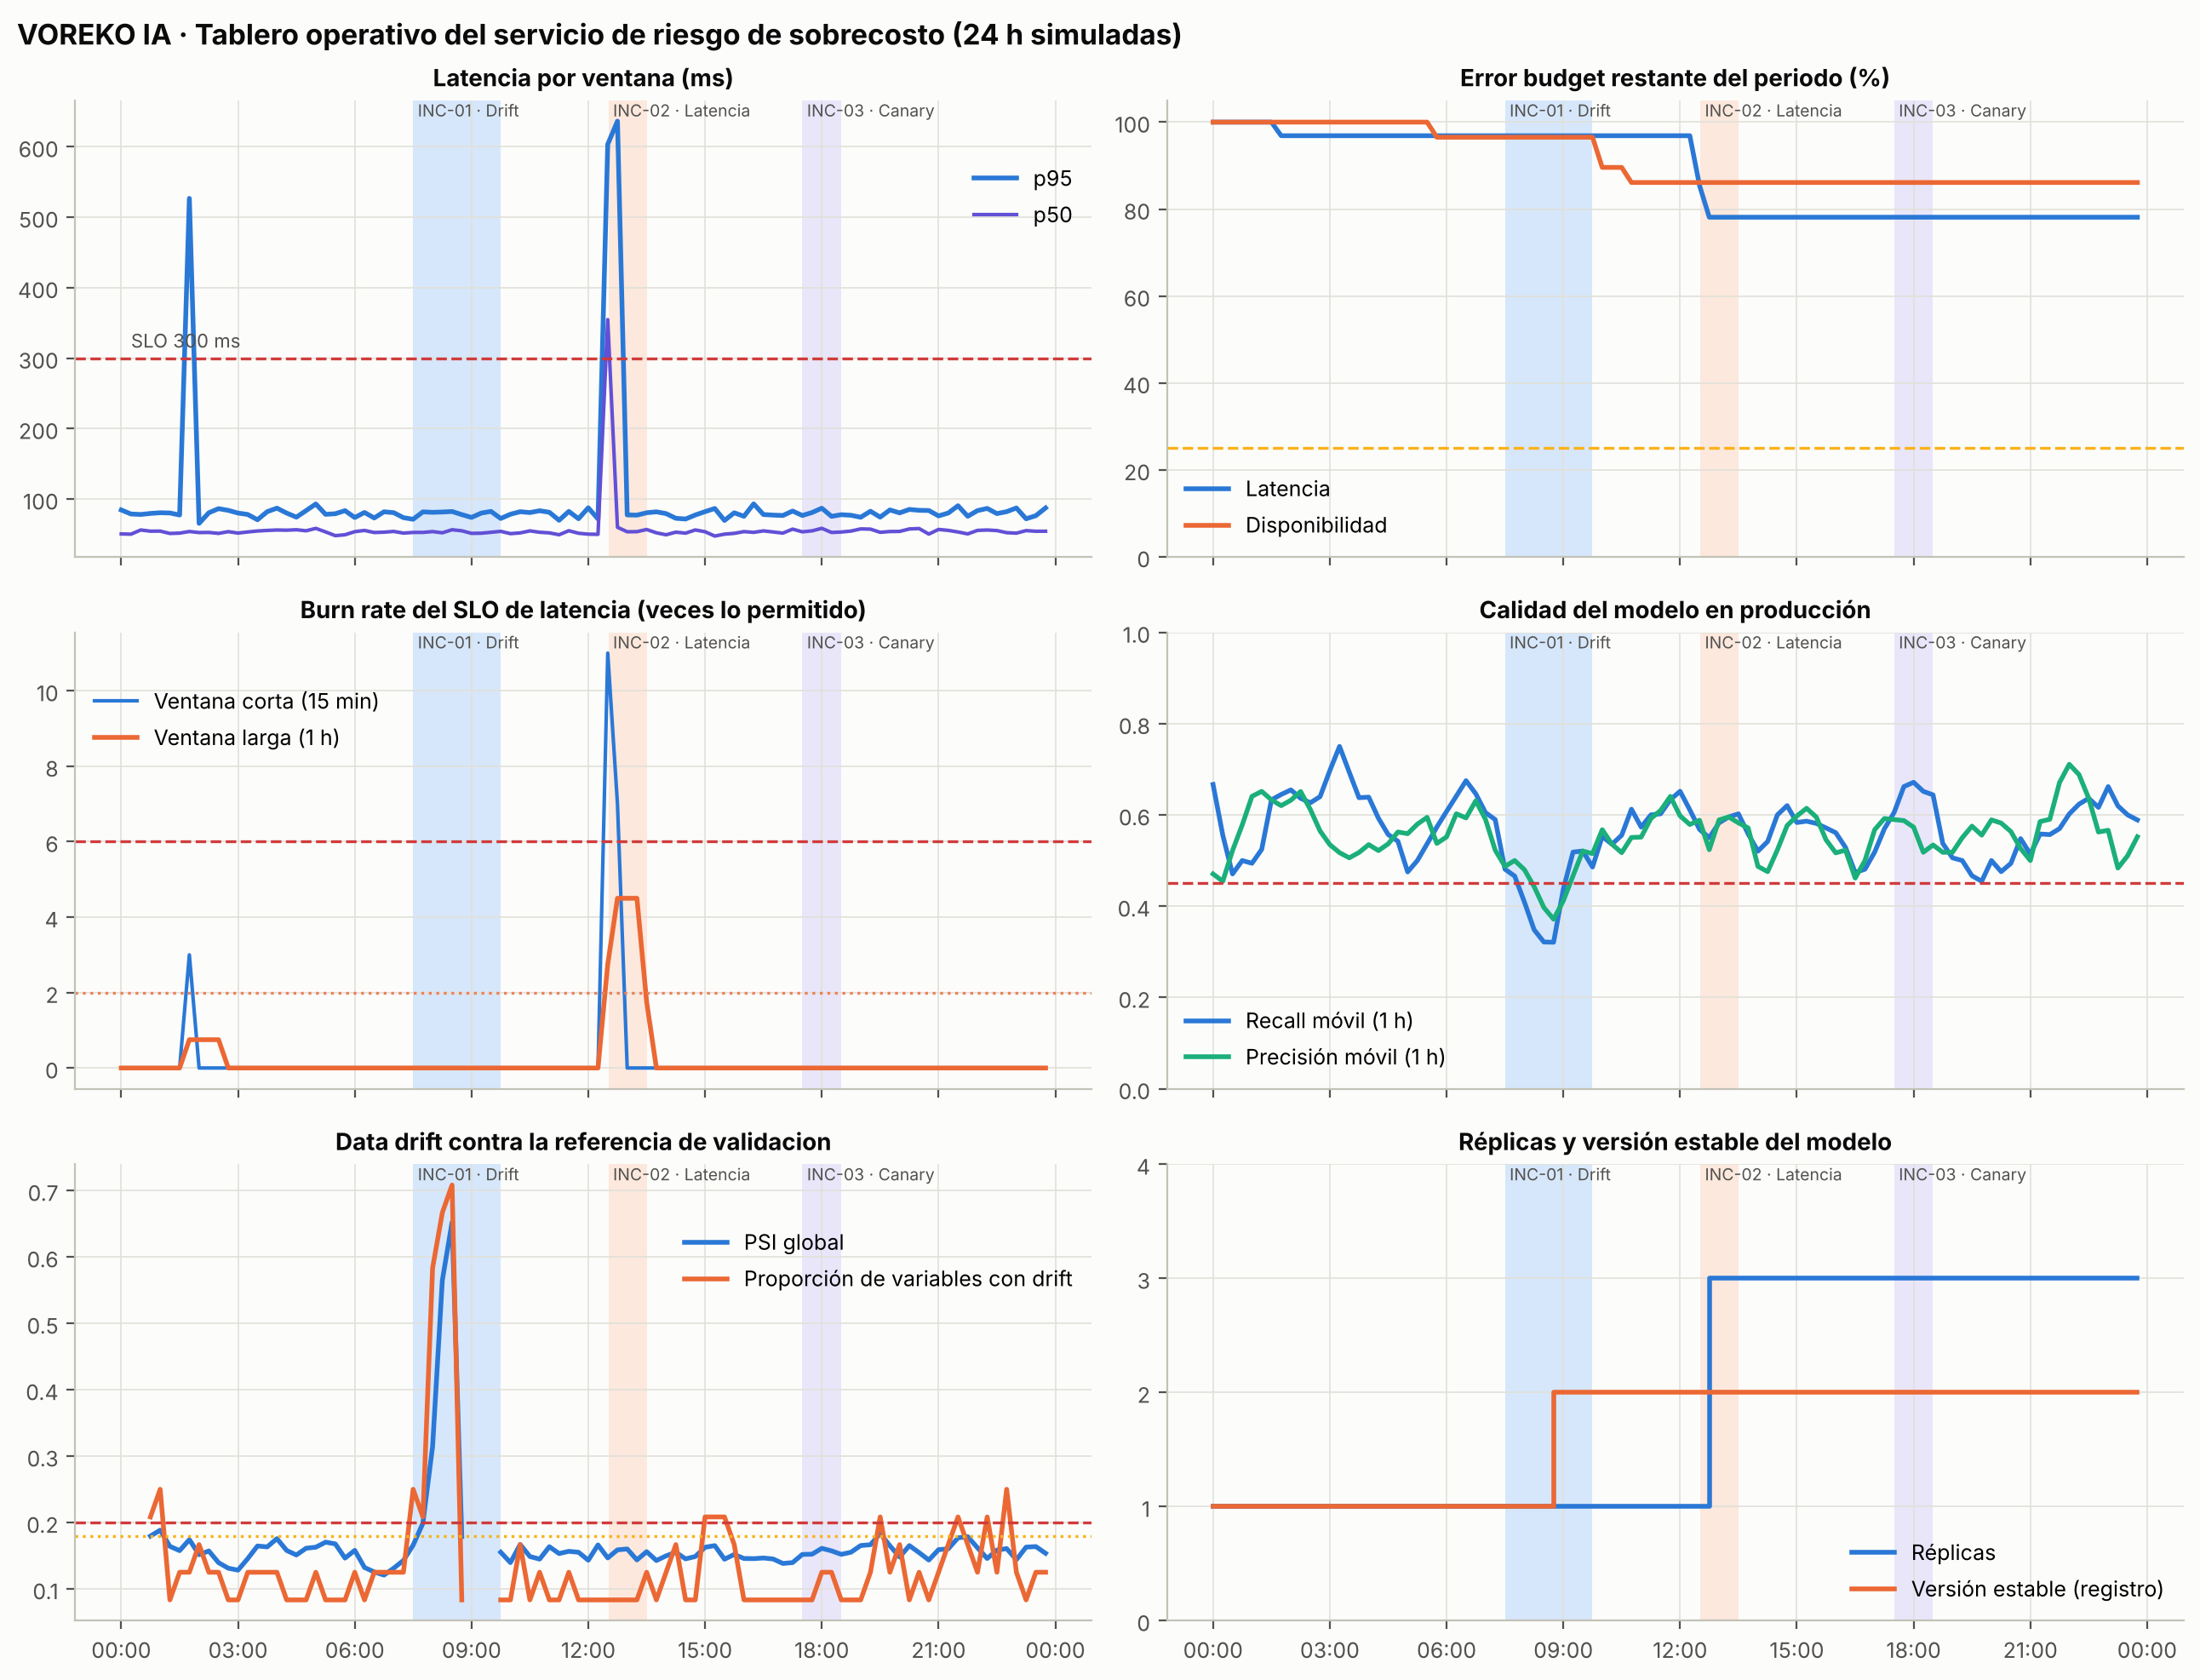

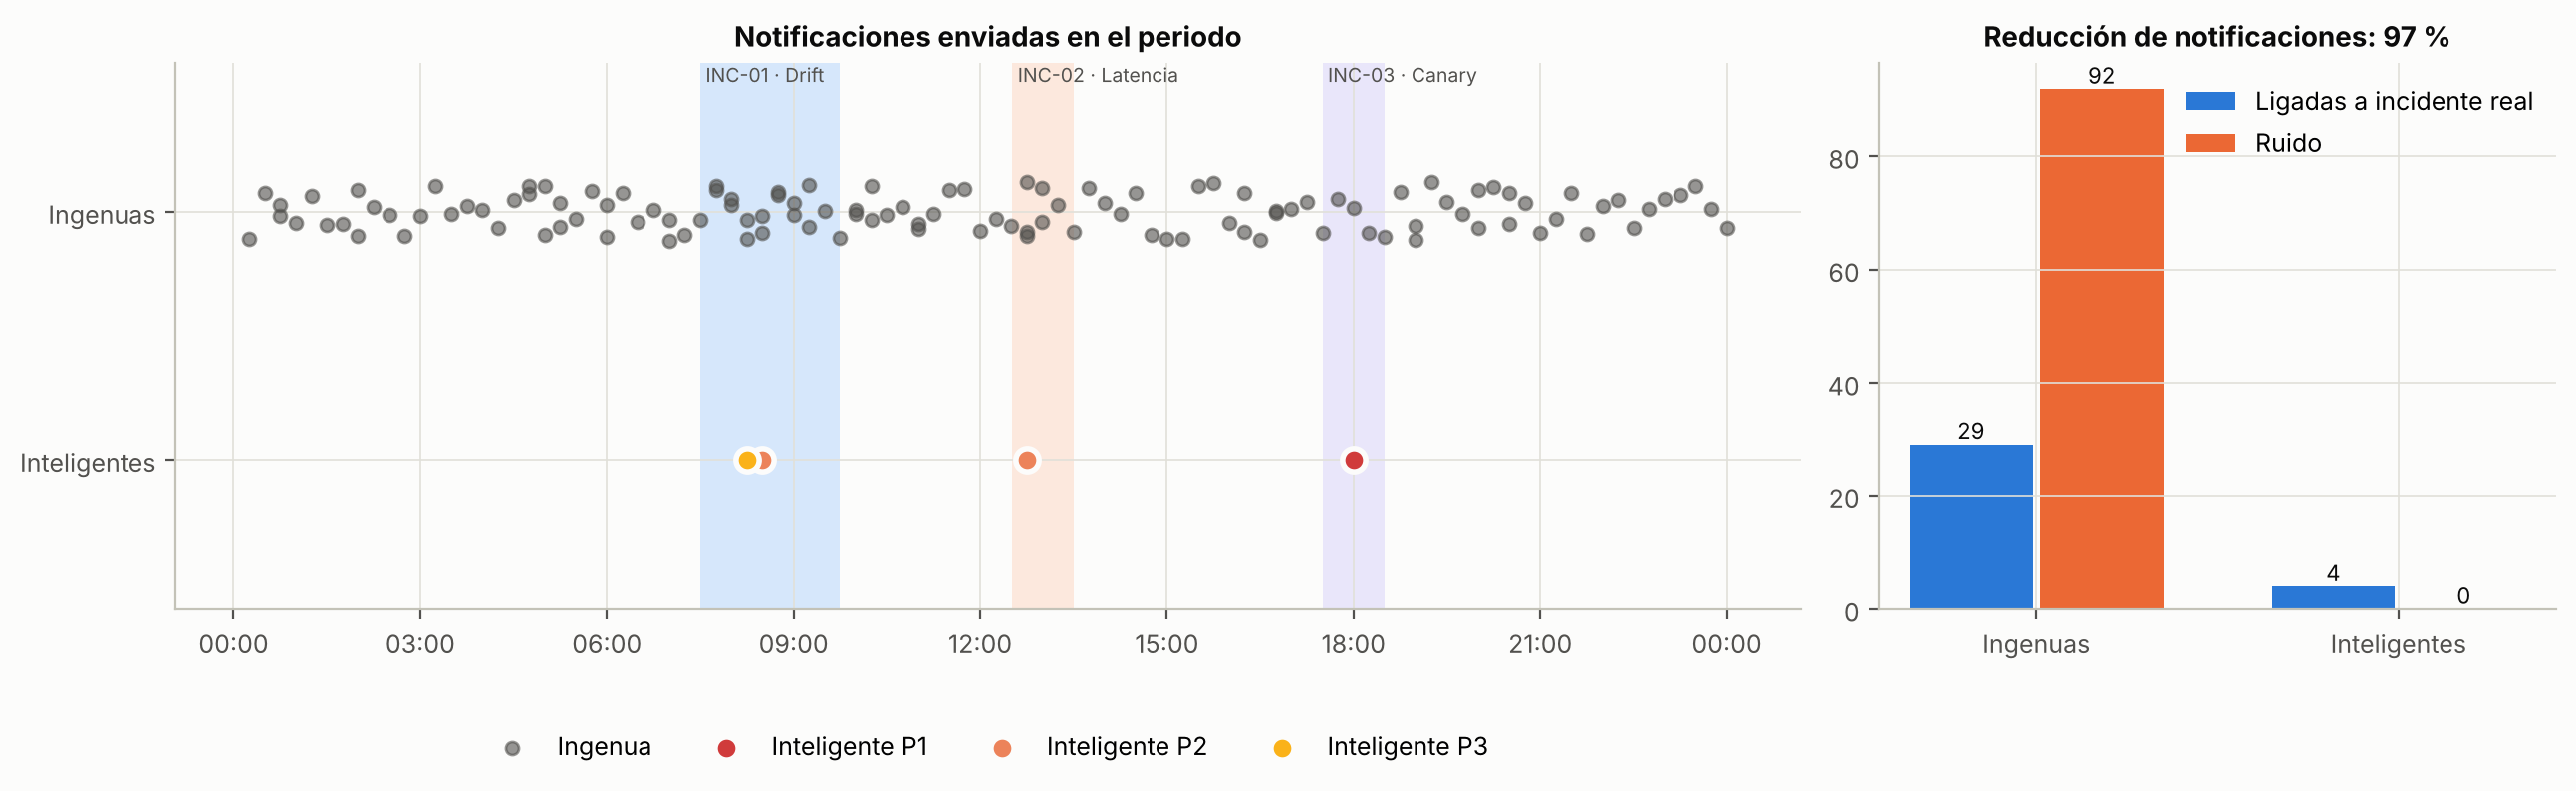

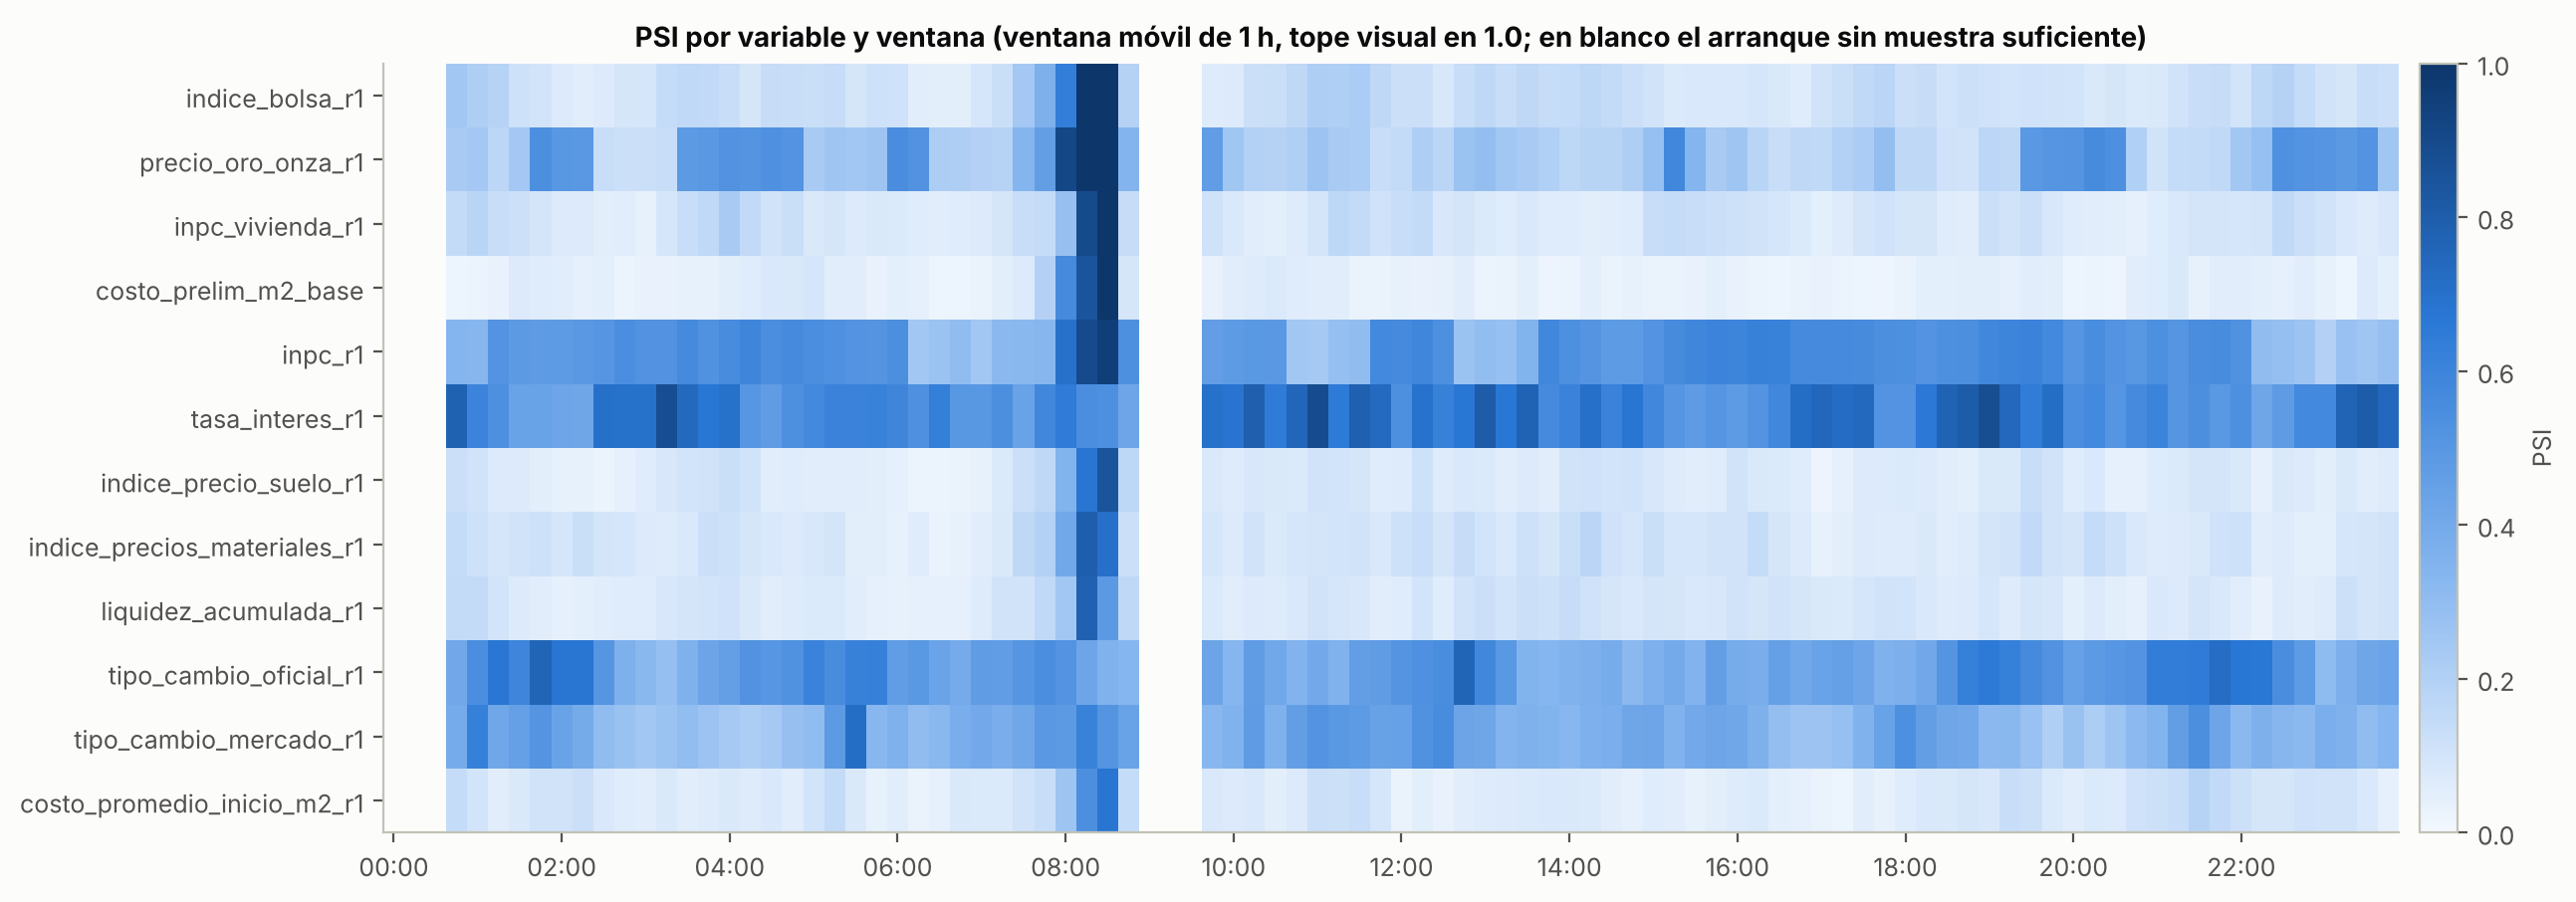

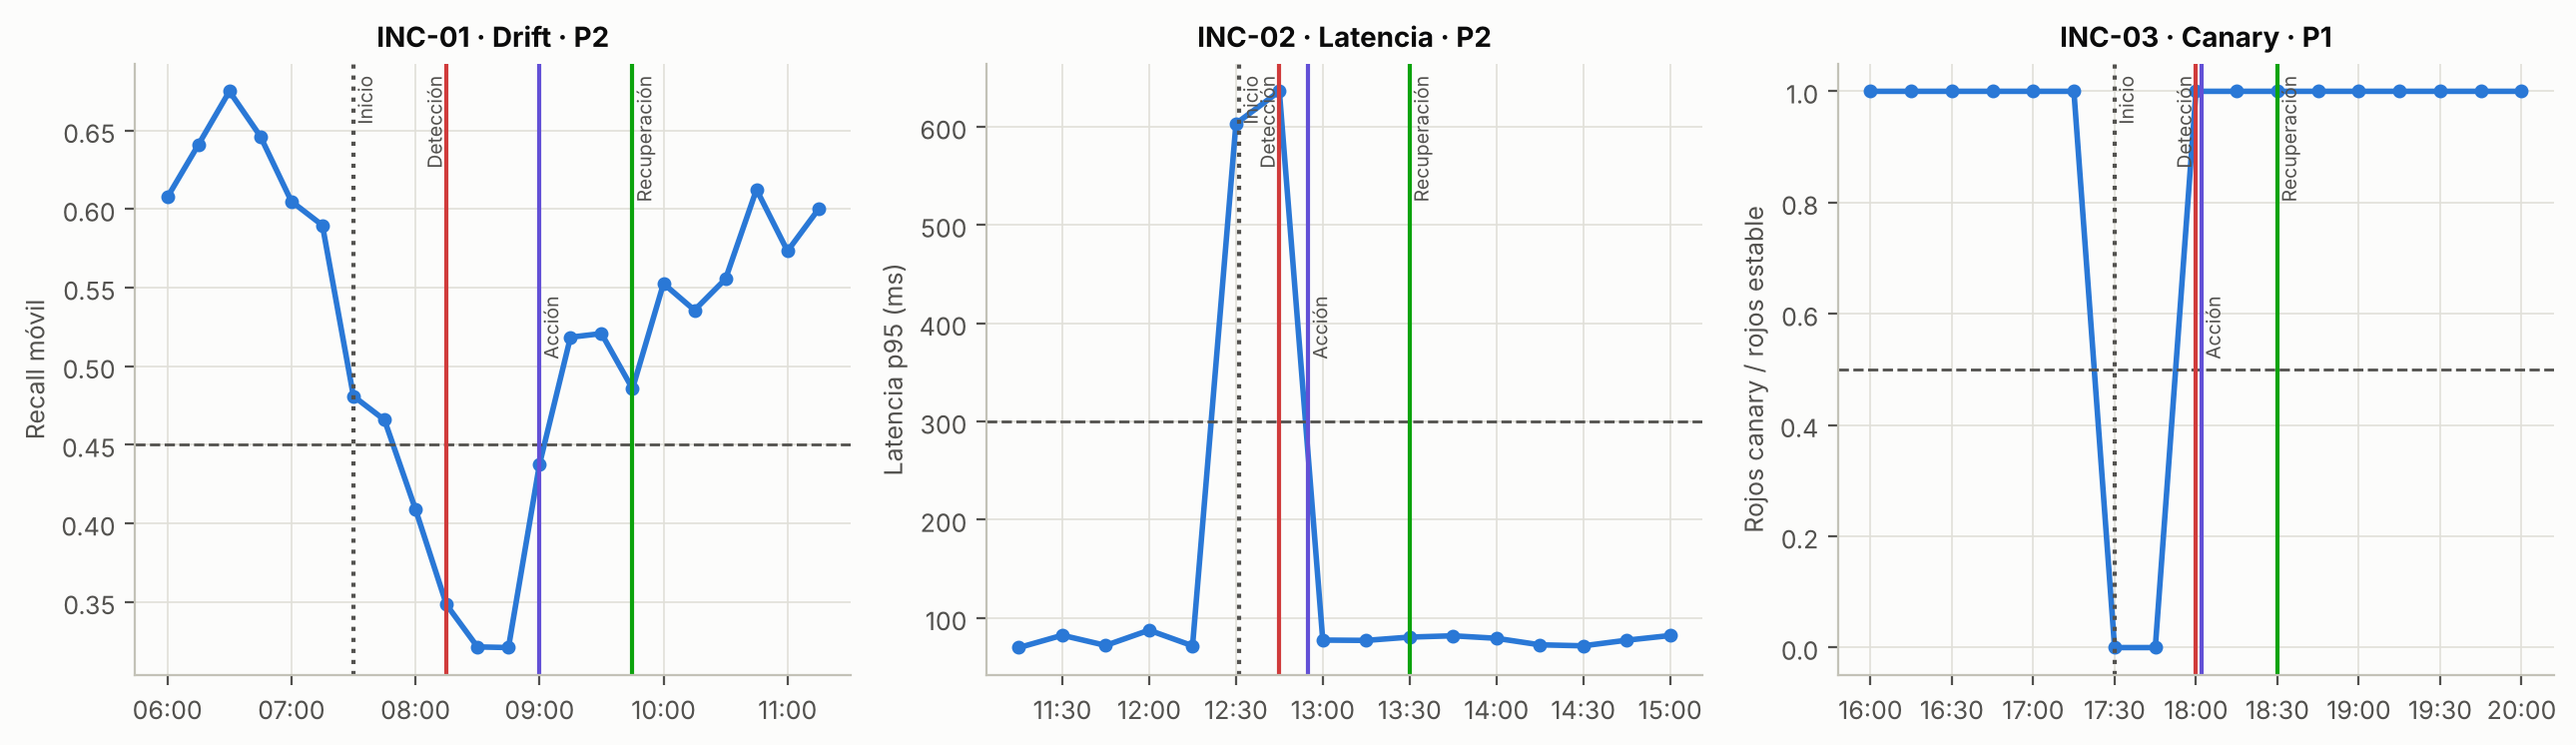

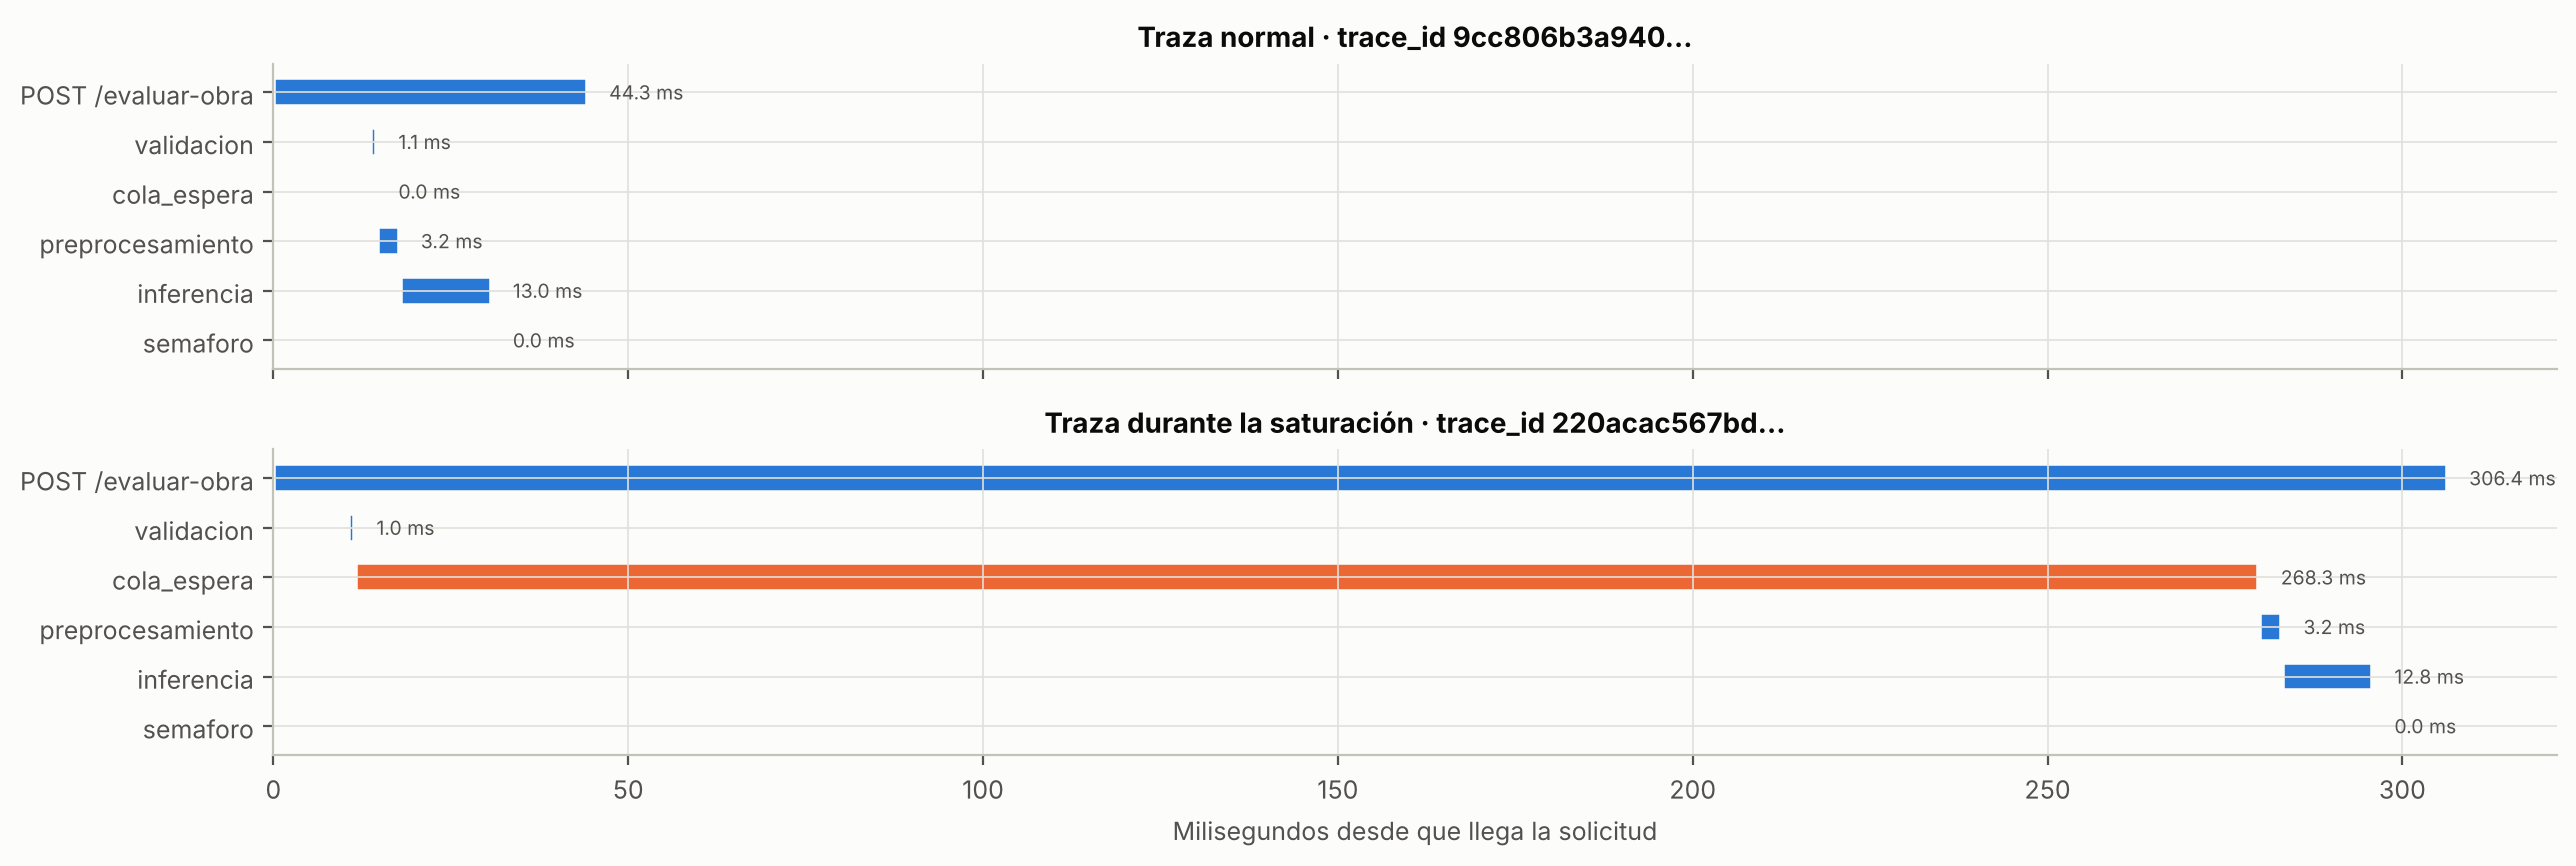

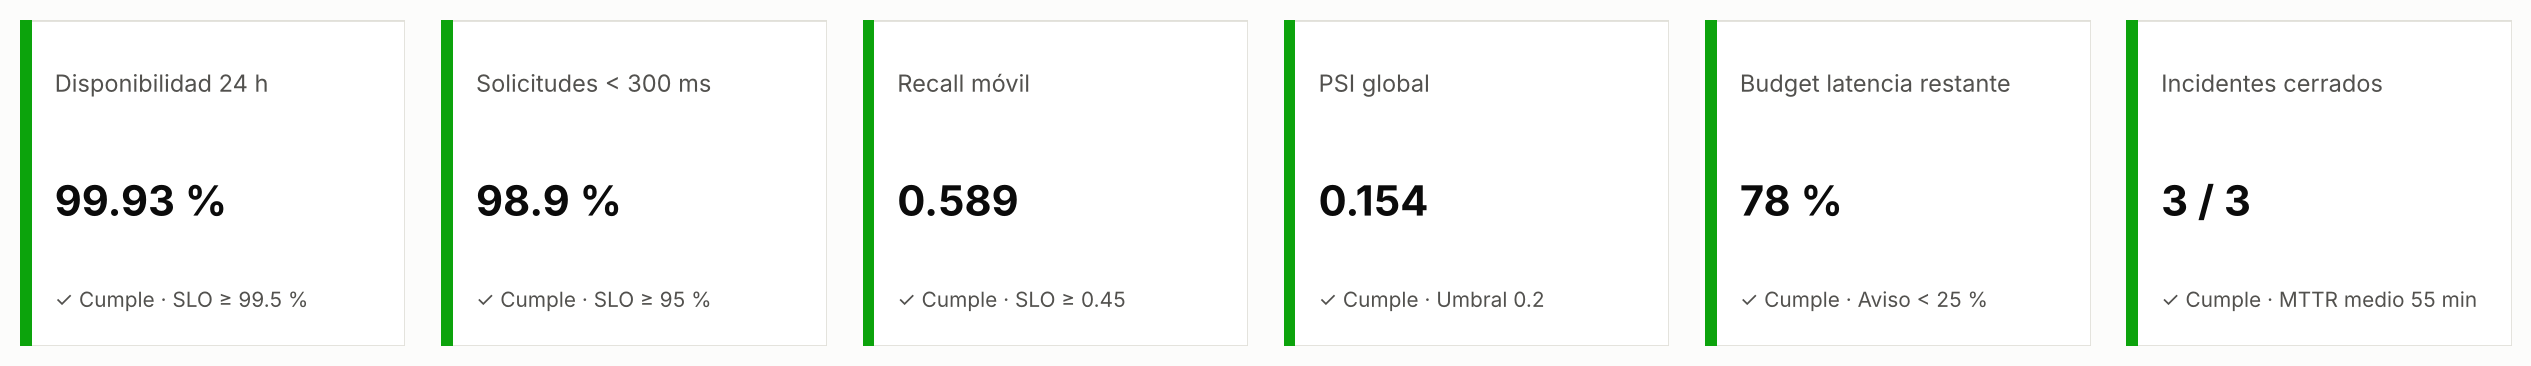

In [16]:
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

try:
    get_ipython().run_line_magic("matplotlib", "inline")
except NameError:
    pass

AZUL, NARANJA, AQUA, VIOLETA = "#2a78d6", "#eb6834", "#1baf7a", "#6250d6"
BUENO, AVISO, SERIO, CRITICO = "#0ca30c", "#fab219", "#ec835a", "#d03b3b"
TINTA, TINTA2, REJILLA, EJE, FONDO = "#0b0b0b", "#52514e", "#e1e0d9", "#c3c2b7", "#fcfcfb"
plt.rcParams.update({"figure.facecolor": FONDO, "axes.facecolor": FONDO, "axes.edgecolor": EJE, "axes.labelcolor": TINTA2, "xtick.color": TINTA2,
                     "ytick.color": TINTA2, "axes.grid": True, "grid.color": REJILLA, "grid.linewidth": 0.6, "axes.spines.top": False,
                     "axes.spines.right": False, "font.size": 9, "axes.titlesize": 10, "axes.titleweight": "bold", "axes.titlecolor": TINTA, "lines.linewidth": 2})
COLOR_INC = {"degradacion_por_drift": "#cde2fb", "saturacion_servicio": "#fde3d6", "version_defectuosa": "#e5e1fa"}
NOMBRE_INC = {"degradacion_por_drift": "Drift", "saturacion_servicio": "Latencia", "version_defectuosa": "Canary"}


def sombrear(ax, etiquetas=True):
    for inc in motor.incidentes:
        ini, fin = INICIO_REAL.get(inc["tipo"], inc["apertura"]), inc["cierre"] or hora(VENTANAS)
        ax.axvspan(ini, fin, color=COLOR_INC.get(inc["tipo"], "#eeeeee"), alpha=0.8, lw=0, zorder=0)
        if etiquetas:
            ax.text(ini, 1.0, f" {inc['id']} · {NOMBRE_INC.get(inc['tipo'], inc['tipo'])}", transform=ax.get_xaxis_transform(), fontsize=7, color=TINTA2, va="top")
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%H:%M"))


fig, ejes = plt.subplots(3, 2, figsize=(13, 10), sharex=True)
ax = ejes[0, 0]; sombrear(ax)
ax.plot(M.hora, M.p95_ms, color=AZUL, label="p95"); ax.plot(M.hora, M.p50_ms, color=VIOLETA, lw=1.5, label="p50")
ax.axhline(umbral_lat, color=CRITICO, ls="--", lw=1.2); ax.text(M.hora.iloc[1], umbral_lat + 15, "SLO 300 ms", color=TINTA2, fontsize=8)
ax.set_title("Latencia por ventana (ms)"); ax.legend(frameon=False, loc="upper right", bbox_to_anchor=(1, 0.9))
ax = ejes[0, 1]; sombrear(ax)
ax.plot(M.hora, 100 * M.presupuesto_lat_restante, color=AZUL, label="Latencia"); ax.plot(M.hora, 100 * M.presupuesto_disp_restante, color=NARANJA, label="Disponibilidad")
ax.axhline(25, color=AVISO, ls="--", lw=1.2); ax.set_ylim(0, 105); ax.set_title("Error budget restante del periodo (%)"); ax.legend(frameon=False, loc="lower left")
ax = ejes[1, 0]; sombrear(ax)
ax.plot(M.hora, M.burn_lat_corta, color=AZUL, lw=1.5, label="Ventana corta (15 min)"); ax.plot(M.hora, M.burn_lat_larga, color=NARANJA, label="Ventana larga (1 h)")
ax.axhline(6, color=CRITICO, ls="--", lw=1.2); ax.axhline(2, color=SERIO, ls=":", lw=1.2); ax.set_title("Burn rate del SLO de latencia (veces lo permitido)"); ax.legend(frameon=False, loc="upper left", bbox_to_anchor=(0, 0.92))
ax = ejes[1, 1]; sombrear(ax)
ax.plot(M.hora, M.recall_movil, color=AZUL, label="Recall móvil (1 h)"); ax.plot(M.hora, M.precision_movil, color=AQUA, label="Precisión móvil (1 h)")
ax.axhline(SLO["calidad"]["recall_minimo"], color=CRITICO, ls="--", lw=1.2); ax.set_ylim(0, 1); ax.set_title("Calidad del modelo en producción"); ax.legend(frameon=False, loc="lower left")
ax = ejes[2, 0]; sombrear(ax)
ax.plot(M.hora, M.psi_global.where(M.n_drift >= 200), color=AZUL, label="PSI global"); ax.plot(M.hora, M.pct_vars_drift.where(M.n_drift >= 200), color=NARANJA, label="Proporción de variables con drift")
ax.axhline(0.2, color=CRITICO, ls="--", lw=1.2); ax.axhline(SLO["datos"]["psi_leve"], color=AVISO, ls=":", lw=1.2); ax.set_title(f"Data drift contra la referencia de {REFERENCIA_DRIFT}"); ax.legend(frameon=False, loc="upper right", bbox_to_anchor=(1, 0.9))
ax = ejes[2, 1]; sombrear(ax)
ax.step(M.hora, M.replicas, where="post", color=AZUL, label="Réplicas"); ax.step(M.hora, M.version_estable, where="post", color=NARANJA, label="Versión estable (registro)")
ax.set_ylim(0, 4); ax.set_yticks([0, 1, 2, 3, 4]); ax.set_title("Réplicas y versión estable del modelo"); ax.legend(frameon=False, loc="lower right")
fig.suptitle("VOREKO IA · Tablero operativo del servicio de riesgo de sobrecosto (24 h simuladas)", fontsize=12, fontweight="bold", color=TINTA, x=0.01, ha="left")
fig.tight_layout(); fig.savefig(SALIDA / "figuras" / "01_tablero_operativo.png", dpi=150); plt.show()

fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 4.2), gridspec_kw={"width_ratios": [2.4, 1]})
sombrear(a1)
a1.scatter(N_ing.hora, np.full(len(N_ing), 1.0) + rng.uniform(-0.12, 0.12, len(N_ing)), s=22, color=TINTA2, alpha=0.6, label="Ingenua", zorder=3)
col_sev = {"P1": CRITICO, "P2": SERIO, "P3": AVISO}
for sev, g in N_int.groupby("severidad"):
    a1.scatter(g.hora, np.zeros(len(g)), s=70, color=col_sev.get(sev, AZUL), edgecolor=FONDO, linewidth=2, label=f"Inteligente {sev}", zorder=4)
a1.set_yticks([0, 1], ["Inteligentes", "Ingenuas"]); a1.set_ylim(-0.6, 1.6); a1.set_title("Notificaciones enviadas en el periodo"); a1.legend(frameon=False, ncol=4, loc="lower center", bbox_to_anchor=(0.5, -0.32))
x = np.arange(2)
a2.bar(x - 0.18, RUIDO.ligadas_a_incidente_real, 0.34, color=AZUL, label="Ligadas a incidente real")
a2.bar(x + 0.18, RUIDO.ruido, 0.34, color=NARANJA, label="Ruido")
for i, r in RUIDO.iterrows():
    a2.text(i - 0.18, r.ligadas_a_incidente_real + 1, str(r.ligadas_a_incidente_real), ha="center", fontsize=8, color=TINTA)
    a2.text(i + 0.18, r.ruido + 1, str(r.ruido), ha="center", fontsize=8, color=TINTA)
a2.set_xticks(x, ["Ingenuas", "Inteligentes"]); a2.set_title(f"Reducción de notificaciones: {REDUCCION:.0f} %"); a2.legend(frameon=False, loc="upper right")
fig.tight_layout(); fig.savefig(SALIDA / "figuras" / "02_reduccion_ruido_alertas.png", dpi=150); plt.show()

PSI_VARS = pd.concat(psi_vars, axis=1)
PSI_VARS.loc[:, (M.n_drift < 200).to_numpy()] = np.nan
top = PSI_VARS.max(axis=1).sort_values(ascending=False).head(12).index
fig, ax = plt.subplots(figsize=(13, 4.6))
im = ax.imshow(PSI_VARS.loc[top].clip(upper=1.0), aspect="auto", cmap=matplotlib.colors.LinearSegmentedColormap.from_list("azul", ["#f3f8fe", "#86b6ef", "#2a78d6", "#0d366b"]), vmin=0, vmax=1.0)
ax.set_yticks(range(len(top)), top); ax.set_xticks(range(0, VENTANAS, 8), [hora(w).strftime("%H:%M") for w in range(0, VENTANAS, 8)]); ax.grid(False)
ax.set_title("PSI por variable y ventana (ventana móvil de 1 h, tope visual en 1.0; en blanco el arranque sin muestra suficiente)")
fig.colorbar(im, ax=ax, fraction=0.02, pad=0.01, label="PSI")
fig.tight_layout(); fig.savefig(SALIDA / "figuras" / "03_drift_psi_por_variable.png", dpi=150); plt.show()

metrica_inc = {"degradacion_por_drift": ("recall_movil", "Recall móvil", SLO["calidad"]["recall_minimo"]), "saturacion_servicio": ("p95_ms", "Latencia p95 (ms)", umbral_lat),
               "version_defectuosa": ("razon_rojo_canary", "Rojos canary / rojos estable", 0.5)}
fig, ejes = plt.subplots(1, len(motor.incidentes), figsize=(13, 3.8))
for ax, inc in zip(np.atleast_1d(ejes), motor.incidentes):
    col, nombre, lim = metrica_inc[inc["tipo"]]
    ini, fin = INICIO_REAL[inc["tipo"]], inc["cierre"] or hora(VENTANAS)
    rango = M[(M.hora >= ini - timedelta(hours=1.5)) & (M.hora <= fin + timedelta(hours=1.5))]
    ax.plot(rango.hora, rango[col], color=AZUL, marker="o", ms=4)
    ax.axhline(lim, color=TINTA2, ls="--", lw=1)
    acc = B[(B.incidente == inc["id"]) & (B.fase == "respuesta")].hora
    for t, c, etiqueta, y_txt in [(ini, TINTA2, "Inicio", 0.98), (inc["apertura"], CRITICO, "Detección", 0.98), (acc.max() if len(acc) else None, VIOLETA, "Acción", 0.62), (inc["cierre"], BUENO, "Recuperación", 0.98)]:
        if t is not None:
            ax.axvline(t, color=c, lw=1.5, ls=":" if etiqueta == "Inicio" else "-")
            ax.text(t, y_txt, f" {etiqueta}", transform=ax.get_xaxis_transform(), rotation=90, va="top", ha="right" if etiqueta == "Detección" else "left", fontsize=7, color=TINTA2)
    ax.set_title(f"{inc['id']} · {NOMBRE_INC[inc['tipo']]} · {inc['severidad']}"); ax.set_ylabel(nombre); ax.xaxis.set_major_formatter(mdates.DateFormatter("%H:%M"))
fig.tight_layout(); fig.savefig(SALIDA / "figuras" / "04_linea_tiempo_incidentes.png", dpi=150); plt.show()

H = pd.DataFrame(registros)
normal = H[(H.ventana == 5) & (H.estado == 200)].iloc[0].trace_id
lenta = H[(H.ventana == EVENTOS["inicio_latencia"] + 1) & (H.cola_ms > 0)].iloc[0].trace_id
spans = exportador.get_finished_spans()
fig, ejes = plt.subplots(2, 1, figsize=(13, 4.4), sharex=True)
for ax, tid, titulo in zip(ejes, [normal, lenta], ["Traza normal", "Traza durante la saturación"]):
    sp = sorted([s for s in spans if format(s.context.trace_id, "032x") == tid], key=lambda s: (s.parent is not None, s.start_time))
    t0 = sp[0].start_time
    for k, s in enumerate(sp):
        d = (s.end_time - s.start_time) / 1e6
        ax.barh(k, max(d, 0.4), left=(s.start_time - t0) / 1e6, color=NARANJA if s.name == "cola_espera" else AZUL, height=0.6, edgecolor=FONDO, linewidth=2)
        ax.text((s.end_time - t0) / 1e6 + 3, k, f"{d:.1f} ms", va="center", fontsize=7, color=TINTA2)
    ax.set_yticks(range(len(sp)), [s.name for s in sp]); ax.invert_yaxis(); ax.set_title(f"{titulo} · trace_id {tid[:12]}…")
ejes[-1].set_xlabel("Milisegundos desde que llega la solicitud")
fig.tight_layout(); fig.savefig(SALIDA / "figuras" / "05_trazas_cascada.png", dpi=150); plt.show()

fin = M.iloc[-1]
tiles = [("Disponibilidad 24 h", f"{100 * (1 - errores_acum / N_PERIODO):.2f} %", f"SLO ≥ {100 * SLO['disponibilidad']['objetivo']:.1f} %", 1 - errores_acum / N_PERIODO >= SLO["disponibilidad"]["objetivo"]),
         ("Solicitudes < 300 ms", f"{100 * (1 - lentas_acum / N_PERIODO):.1f} %", f"SLO ≥ {100 * SLO['latencia']['objetivo']:.0f} %", 1 - lentas_acum / N_PERIODO >= SLO["latencia"]["objetivo"]),
         ("Recall móvil", f"{fin.recall_movil:.3f}", f"SLO ≥ {SLO['calidad']['recall_minimo']}", fin.recall_movil >= SLO["calidad"]["recall_minimo"]),
         ("PSI global", f"{fin.psi_global:.3f}", f"Umbral {SLO['datos']['psi_umbral']}", fin.psi_global <= SLO["datos"]["psi_umbral"]),
         ("Budget latencia restante", f"{100 * fin.presupuesto_lat_restante:.0f} %", "Aviso < 25 %", fin.presupuesto_lat_restante >= 0.25),
         ("Incidentes cerrados", f"{int(INC.resuelto.sum())} / {len(INC)}", f"MTTR medio {INC.MTTR_min.mean():.0f} min", bool(INC.resuelto.all()))]
fig, ejes = plt.subplots(1, len(tiles), figsize=(13, 1.9))
for ax, (titulo, valor, meta, cumple) in zip(ejes, tiles):
    ax.axis("off")
    ax.add_patch(plt.Rectangle((0, 0), 1, 1, transform=ax.transAxes, facecolor="white", edgecolor=REJILLA, lw=1))
    ax.add_patch(plt.Rectangle((0, 0), 0.03, 1, transform=ax.transAxes, facecolor=BUENO if cumple else CRITICO, lw=0))
    ax.text(0.09, 0.78, titulo, fontsize=8.5, color=TINTA2, transform=ax.transAxes)
    ax.text(0.09, 0.40, valor, fontsize=15, fontweight="bold", color=TINTA, transform=ax.transAxes)
    ax.text(0.09, 0.12, ("✓ Cumple · " if cumple else "✕ No cumple · ") + meta, fontsize=7.5, color=TINTA2, transform=ax.transAxes)
fig.tight_layout(); fig.savefig(SALIDA / "figuras" / "06_estado_slo.png", dpi=150); plt.show()

## 17. Registro final en MLflow y exportación de evidencias

In [17]:
spans_json = []
ids_muestra = set(H[H.ventana.isin([5, EVENTOS["inicio_latencia"] + 1])].trace_id) | set(H[H.estado != 200].trace_id) | set(H[H.es_canary].trace_id.head(30))
for s in spans:
    tid = format(s.context.trace_id, "032x")
    if tid in ids_muestra:
        spans_json.append({"trace_id": tid, "span_id": format(s.context.span_id, "016x"), "padre": format(s.parent.span_id, "016x") if s.parent else None, "nombre": s.name,
                           "inicio": datetime.fromtimestamp(s.start_time / 1e9).isoformat(timespec="milliseconds"), "duracion_ms": round((s.end_time - s.start_time) / 1e6, 3),
                           "estado": s.status.status_code.name, "atributos": dict(s.attributes)})
(SALIDA / "trazas" / "trazas_muestra.json").write_text(json.dumps(spans_json, ensure_ascii=False, indent=1, default=str), encoding="utf-8")
H.drop(columns=["fila"]).to_csv(SALIDA / "tablas" / "solicitudes.csv", index=False)
M.to_csv(SALIDA / "tablas" / "metricas_por_ventana.csv", index=False)
PSI_VARS.T.to_csv(SALIDA / "tablas" / "psi_por_variable.csv", index_label="ventana")
pd.DataFrame(motor.eventos).to_csv(SALIDA / "tablas" / "eventos_alertas.csv", index=False)
N_int.to_csv(SALIDA / "tablas" / "notificaciones_inteligentes.csv", index=False)
N_ing.to_csv(SALIDA / "tablas" / "notificaciones_ingenuas.csv", index=False)
INC.to_csv(SALIDA / "tablas" / "incidentes.csv", index=False)
B.to_csv(SALIDA / "tablas" / "bitacora_runbooks.csv", index=False)
RUIDO.to_csv(SALIDA / "tablas" / "reduccion_ruido.csv", index=False)
pd.DataFrame([{"runbook": k, **x} for k, x in RUNBOOKS.items()]).to_csv(SALIDA / "tablas" / "runbooks.csv", index=False)
manejador.flush()

mlflow.log_metrics({"resumen_disponibilidad": 1 - errores_acum / N_PERIODO, "resumen_cumplimiento_latencia": 1 - lentas_acum / N_PERIODO,
                    "resumen_notificaciones_ingenuas": len(N_ing), "resumen_notificaciones_inteligentes": len(N_int), "resumen_reduccion_ruido_pct": REDUCCION,
                    "resumen_mttd_medio_min": float(INC.MTTD_min.mean()), "resumen_mttr_medio_min": float(INC.MTTR_min.mean())})
for carpeta in ["figuras", "tablas", "trazas", "logs"]:
    mlflow.log_artifacts(str(SALIDA / carpeta), carpeta)
mlflow.set_tags({"proyecto": "VOREKO IA", "actividad": "A8", "modelo": NOMBRE_MODELO})
padre = mlflow.active_run().info.run_id
for r in INC.itertuples():
    with mlflow.start_run(run_name=f"{r.incidente}_{r.tipo}", nested=True):
        mlflow.log_params({"tipo": r.tipo, "severidad": r.severidad_final, "reglas": r.reglas, "diagnostico": r.diagnostico})
        mlflow.log_metrics({"MTTD_min": r.MTTD_min, "MTTR_min": r.MTTR_min, "resuelto": int(r.resuelto), "diagnostico_correcto": int(r.diagnostico_correcto)})
        mlflow.log_table(B[B.incidente == r.incidente].astype(str), artifact_file=f"bitacora_{r.incidente}.json")
mlflow.end_run()

versiones = [{"version": mv.version, "aliases": ", ".join(client.get_model_version(NOMBRE_MODELO, mv.version).aliases), "umbral_rojo": mv.tags.get("umbral_rojo"),
              "estado": mv.tags.get("estado", "vigente"), "descripcion": mv.description} for mv in client.search_model_versions(f"name='{NOMBRE_MODELO}'")]
REGISTRO = pd.DataFrame(versiones).sort_values("version")
REGISTRO.to_csv(SALIDA / "tablas" / "registro_modelos.csv", index=False)
print("Run principal:", padre)
REGISTRO

Run principal: 72442dc31b9c4bb592dd34038600d9fc


,version,aliases,umbral_rojo,estado,descripcion
2,1,anterior,0.39,vigente,Modelo estable de la Fase II (umbral 0.39).
1,2,champion,0.39,vigente,Reentrenado por INC-01 con precios actualizados.
0,3,,0.7,rechazado_por_rollback,Release candidata desplegada en canary al 20 %.


## 18. Interfaz de MLflow

In [18]:
try:
    from google.colab import output
    subprocess.Popen(["mlflow", "ui", "--backend-store-uri", f"sqlite:///{SALIDA / 'mlflow.db'}", "--port", "5000"], stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL)
    time.sleep(8)
    output.serve_kernel_port_as_window(5000)
except ImportError:
    print(f"mlflow ui --backend-store-uri sqlite:///{SALIDA / 'mlflow.db'} --port 5000")

mlflow ui --backend-store-uri sqlite:////content/actividad8_salidas/mlflow.db --port 5000
